# 03 · DeFakeNet-Lite: final experiments (40 epochs)

**Project:** detecting real vs AI-generated (StyleGAN) face images with a lightweight model
**Author:** Arman Rahman, BSc CSE, East Delta University · **Supervisor:** Md. Jamil Uddin
**Base paper:** D. Samal *et al.*, "DeFakeNet: A ResNet50V2-based deep learning model for deepfake detection and classification", *JIIP* 7(4), 2025 · reported **91.95 %** test accuracy
**Dataset:** RVF10K, balanced splits (Zenodo 10.5281/zenodo.14532968), 6,000 train / 2,000 validation / 2,000 test

**DeFakeNet-Lite** = MobileNetV3-Large (width 0.75, ImageNet-pretrained) + a compact head (Dropout → Dense 128 → Dropout → sigmoid) + our training recipe. 1.90 M parameters against DeFakeNet's 25.66 M.

## Research questions and where each is answered

| RQ | Question | Where |
| --- | --- | --- |
| **RQ1** | Is DeFakeNet's result limited by its **architecture** or by its **training recipe**, and which part of the recipe matters? | 10.1 DeFakeNet with our recipe, 3 seeds · 10.3 ablation · 10.4 the paper's 0–1 pixel scaling |
| **RQ2** | Can a much **lighter** model (DeFakeNet-Lite) keep the same accuracy? | 10.1 DeFakeNet-Lite, 3 seeds + McNemar test · 10.2 same-machine cost |
| **RQ3** | How well do the detectors **generalise** to unseen datasets and other kinds of fakes? | 10.5 cross-dataset test (StyleGAN 140k, Stable Diffusion XL faces, OpenForensics), no retraining |

## What this notebook trains and what it reuses

| Part | Runs | Epochs | Source |
| --- | --- | --- | --- |
| Main result (RQ1, RQ2, RQ3) | DeFakeNet + our recipe and DeFakeNet-Lite, seeds 42, 1, 2 (6 runs) | **40** (5 frozen + 35 fine-tune; the paper's maximum was 40) | **trained here**, about 5 h on one T4 |
| Ablation (RQ1) | DeFakeNet-Lite, full recipe + 7 runs with one part switched back, seed 42 | 30 | **reused** from notebook 02, all 8 runs from one session |
| Paper's 0–1 pixel scaling (RQ1) | DeFakeNet + our recipe with 0–1 input, seed 42 | 30 | **reused** from notebook 02 |

The ablation is a comparison *inside one experiment*: all its runs share the same 30-epoch budget, so it stays fair. Nothing is typed in by hand except the base paper's reported numbers.

## 1. Settings and imports

In [1]:
RUN_GROUPS = ["main", "seeds"]   # main = seed 42 of both models; seeds = seeds 1 and 2 (6 runs, ~5 h)
SEEDS = (42, 1, 2)               # 3 seeds per model -> mean ± std
EXTERNAL_MAX_PER_CLASS = 1000    # images per class from each cross-dataset set

import os, time, json, random, gc, hashlib, glob, io, contextlib, subprocess, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image
try: print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
except FileNotFoundError: print("nvidia-smi not found (no GPU)")
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU       :", tf.config.list_physical_devices("GPU"))

Thu Nov  5 14:11:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Load the saved runs of notebook 02 (ablation and 0–1 scaling, reused, not retrained)

Every run of notebook 02 saved `<run>_results.json` (all numbers, training history, settings) and `<run>_probs.npz` (the model's score for each of the 2,000 test images). They are read here from the attached output of notebook 02 (the same files are in `results/02_ablation_30_epochs/` of this repository; attach that folder as a Kaggle dataset to use them). The scores are needed for the McNemar tests.

In [2]:
PREV, PREV_PROBS = {}, {}   # key -> results (notebook 02, 30 epochs) and path of its test scores
for f in sorted(glob.glob("/kaggle/input/**/*_results.json", recursive=True)):
    try: r = json.load(open(f))
    except Exception: continue
    npz = f[:-len("_results.json")] + "_probs.npz"
    if all(k in r for k in ("key", "model", "tag", "seed", "test")) and os.path.exists(npz):
        PREV[r["key"]], PREV_PROBS[r["key"]] = r, npz

ABL_TAGS = {   # tag: the one part switched back to the old DeFakeNet way
    "size224":   "images shrunk to 224 x 224",
    "heavyAug":  "old heavy augmentation (rotate, 20% shift, zoom, upside-down flips)",
    "noWarmup":  "no frozen warm-up (30 epochs of full fine-tuning)",
    "noEMA":     "no EMA weight averaging",
    "trainBN":   "BatchNorm not frozen",
    "noLS":      "no label smoothing",
    "plainAdam": "plain Adam with a constant learning rate",
}
PREV_LITE = "MobileNetV3L_a075"            # DeFakeNet-Lite's name in notebook 02
ABL_REF = f"{PREV_LITE}__full__s42"        # full recipe, 30 epochs: the ablation reference
K01 = "DeFakeNet_NR__paper01__s42"         # DeFakeNet + our recipe, the paper's 0..1 input
need = [ABL_REF, K01] + [f"{PREV_LITE}__{t}__s42" for t in ABL_TAGS]
print(len(PREV), "saved runs found in the attached input:")
for k in sorted(PREV): print(f"  {k:40s} acc {PREV[k]['test']['thr=0.5']['acc']:.2f} | {PREV[k].get('epochs_run', '?')} epochs")
missing = [k for k in need if k not in PREV]
if missing:
    raise RuntimeError("STOP: these saved runs of notebook 02 were not found: " + ", ".join(missing) +
                     "\nAttach the output of notebook 02 (or results/02_ablation_30_epochs) first: Add Input")
print("All saved runs needed for the ablation and the 0-1 scaling test are here.")

13 saved runs found in the attached input:
  DeFakeNet_NR__full__s1                   acc 98.35 | 30 epochs
  DeFakeNet_NR__full__s2                   acc 98.70 | 30 epochs
  DeFakeNet_NR__paper01__s42               acc 98.40 | 30 epochs
  MobileNetV3L_a075__full__s1              acc 98.30 | 30 epochs
  MobileNetV3L_a075__full__s2              acc 98.35 | 30 epochs
  MobileNetV3L_a075__full__s42             acc 98.45 | 30 epochs
  MobileNetV3L_a075__heavyAug__s42         acc 94.60 | 30 epochs
  MobileNetV3L_a075__noEMA__s42            acc 98.50 | 30 epochs
  MobileNetV3L_a075__noLS__s42             acc 98.60 | 30 epochs
  MobileNetV3L_a075__noWarmup__s42         acc 99.05 | 30 epochs
  MobileNetV3L_a075__plainAdam__s42        acc 99.05 | 30 epochs
  MobileNetV3L_a075__size224__s42          acc 98.00 | 30 epochs
  MobileNetV3L_a075__trainBN__s42          acc 98.25 | 30 epochs
All saved runs needed for the ablation and the 0-1 scaling test are here.


## 3. Dataset: RVF10K

Same Zenodo record as the base paper. The folder called `6040` is really a **60 / 20 / 20** split: 6,000 train, 2,000 validation, 2,000 test, half real (FFHQ) and half fake (StyleGAN). The test set is never used for training or for choosing anything.

In [3]:
import requests, zipfile
RECORD_ID = "14532968"
meta = requests.get(f"https://zenodo.org/api/records/{RECORD_ID}").json()
os.makedirs("/content/data", exist_ok=True)
for f in meta["files"]:
    dest = f"/content/{f['key']}"
    if not os.path.exists(dest):
        print("Downloading", f["key"], "...")
        subprocess.run(["wget", "-q", "-O", dest, f["links"]["self"]], check=True)
    if f["key"].lower().endswith(".zip") and not os.path.isdir("/content/data/Real vs Fake Faces"):
        print("Extracting ...")
        with zipfile.ZipFile(dest) as z:
            z.extractall("/content/data")
DATA_BASE = "/content/data"

def find_split_root(base, tokens=("60-40", "60_40", "6040")):
    for root, dirs, _ in os.walk(base):
        if any(t in os.path.basename(root).lower().replace(" ", "") for t in tokens):
            return root
    return None

def pick(parent, names):
    for n in names:
        p = os.path.join(parent, n)
        if os.path.isdir(p): return p

DATA_ROOT = find_split_root(DATA_BASE) or DATA_BASE
TRAIN_DIR = pick(DATA_ROOT, ["train", "training", "Train"])
VAL_DIR   = pick(DATA_ROOT, ["valid", "val", "validation", "Valid"])
TEST_DIR  = pick(DATA_ROOT, ["test", "testing", "Test"])
for d in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    print(d, {c: len(os.listdir(os.path.join(d, c))) for c in sorted(os.listdir(d))})

Extracting ...
/content/data/Real vs Fake Faces/6040/train {'fake': 3000, 'real': 3000}
/content/data/Real vs Fake Faces/6040/valid {'fake': 1000, 'real': 1000}
/content/data/Real vs Fake Faces/6040/test {'fake': 1000, 'real': 1000}


## 4. The training recipe: DeFakeNet paper vs ours

| Setting | DeFakeNet paper | Our recipe | Why |
| --- | --- | --- | --- |
| Image size | shrunk to 224 × 224 | full 256 × 256 | keeps the fine pixel detail where GAN traces live |
| Augmentation | heavy: rotation, 20% shift, zoom, shear, **upside-down flips** | gentle: left-right flip + 5% shift | faces are never upside down; heavy changes hide the fake traces |
| Pixel scaling | 0 to 1 | what the backbone was pre-trained with (ResNet50V2: −1 to 1) | matches ImageNet pre-training |
| Epochs | up to 40, all layers trained from the start | **40**: 5 with the backbone frozen, then 35 fine-tuning | the new head learns first, so it does not damage the pre-trained body |
| Optimiser | Adam 1e-4, halved when validation loss stalls | AdamW + 1-epoch warm-up + cosine decay | smoother, more stable training |
| Weight averaging | none | EMA of the weights (0.995) | a calmer, less noisy final model |
| BatchNorm | trainable | frozen (inference mode) | small batches make BatchNorm statistics noisy |
| Label smoothing | 0 | 0.05 | the model is less over-confident |
| Early stopping | validation loss, patience 5 | EMA validation loss, patience 8, not before fine-tune epoch 15 | avoids stopping on an early noisy epoch |

In [4]:
_f = os.path.join(TRAIN_DIR, "fake"); _w, _h = Image.open(os.path.join(_f, sorted(os.listdir(_f))[0])).size
NATIVE = int(min(max(round(min(_w, _h) / 32) * 32, 224), 256))      # 256 for this dataset
print("native input size:", NATIVE)

BASE_CFG = dict(
    img=NATIVE,           # full-size images (paper: 224)
    aug="gentle",         # left-right flip + 5% shift (paper: heavy, incl. upside-down flips)
    scale=None,           # None = what the backbone expects (ResNet50V2: -1..1)
    warmup=5,             # epochs with the backbone frozen
    ft=35,                # fine-tune epochs -> 40 epochs in total, the paper's maximum
    ema=0.995,            # EMA of the weights
    freeze_bn=True,       # BatchNorm kept in inference mode
    label_smooth=0.05,
    opt="adamw_cos",      # AdamW + warm-up + cosine decay
)
WARMUP_LR, FT_LR, FT_LR_WARM_EPOCHS = 1e-3, 1e-4, 1
HEAD_DROP, WEIGHT_DECAY = 0.3, 1e-4
ES_PATIENCE, ES_MIN_EPOCHS = 8, 15
BATCH_SIZE, WEIGHTS = 32, "imagenet"

OUTDIR = "/kaggle/working/defakenet_lite_output"
os.makedirs(OUTDIR, exist_ok=True)

MIXED = bool(tf.config.list_physical_devices("GPU"))
if MIXED:
    keras.mixed_precision.set_global_policy("mixed_float16")
print("Policy:", keras.mixed_precision.global_policy().name)

native input size: 256
Policy: mixed_float16


## 5. Input pipeline (images are decoded once and cached; augmentation runs on the GPU inside the model)

In [5]:
AUTOTUNE = tf.data.AUTOTUNE
_DATA = {}

def make_ds(directory, training, size):
    ds = keras.utils.image_dataset_from_directory(
        directory, labels="inferred", label_mode="binary", class_names=["fake", "real"],
        image_size=(size, size), batch_size=None, shuffle=False)
    ds = ds.map(lambda x, y: (tf.cast(tf.round(x), tf.uint8), y), num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(2048, seed=42, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

def get_data(size):
    if size not in _DATA:
        tr, va, te = make_ds(TRAIN_DIR, True, size), make_ds(VAL_DIR, False, size), make_ds(TEST_DIR, False, size)
        y_va = np.concatenate([y.numpy().ravel() for _, y in va]).astype(int)
        y_te = np.concatenate([y.numpy().ravel() for _, y in te]).astype(int)
        _DATA[size] = dict(train=tr, val=va, test=te, y_val=y_va, y_test=y_te,
                           steps=int(tf.data.experimental.cardinality(tr).numpy()))
    return _DATA[size]

D = get_data(NATIVE)
y_test = D["y_test"]
print("steps/epoch:", D["steps"], "| val:", len(D["y_val"]), "| test:", len(y_test))

Found 6000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.
steps/epoch: 188 | val: 2000 | test: 2000


## 6. Other datasets for the cross-dataset test (RQ3)

Downloaded automatically from Hugging Face (no login), 1,000 real + 1,000 fake each. The models are **not retrained** on them.

| Set | Fakes | Reals | Source |
| --- | --- | --- | --- |
| `stylegan_140k` | StyleGAN (same kind as training, new images) | FFHQ | Kaggle "140k Real and Fake Faces" (xhlulu), mirror `TheKernel01/140k-Real-and-Fake-Faces`, test split |
| `sdxl_faces` | Stable Diffusion XL faces (diffusion, a newer kind of AI-generated image) | CelebA-HQ | `bitmind/celeb-a-hq___stable-diffusion-xl-base-1.0___256_training_faces` + `korexyz/celeba-hq-256x256` |
| `openforensics` | face-swap / manipulated faces in the wild | in-the-wild faces | Kaggle "Deepfake and Real Images" (manjilkarki), mirror `Hemg/deepfake-and-real-images` |

Any image that is **byte-for-byte identical to an RVF10K image is removed** (and, for the 140k set, any file with an RVF10K file name), so a model is never tested on a photo it trained on.

In [6]:
import pyarrow.parquet as pq
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")
EXT_DL = "/kaggle/working/external"
HF = "https://huggingface.co/datasets"
XSETS = {   # name: [(parquet url, label or {label value: class})]
    "stylegan_140k": [(f"{HF}/TheKernel01/140k-Real-and-Fake-Faces/resolve/main/data/test-00000-of-00002.parquet", {0: "real", 1: "fake"})],
    "sdxl_faces":    [(f"{HF}/bitmind/celeb-a-hq___stable-diffusion-xl-base-1.0___256_training_faces/resolve/main/base_transforms/train-00000-of-00004.parquet", "fake"),
                      (f"{HF}/korexyz/celeba-hq-256x256/resolve/main/data/validation-00000-of-00001.parquet", "real")],
    "openforensics": [(f"{HF}/Hemg/deepfake-and-real-images/resolve/main/data/train-00000-of-00005.parquet", {0: "fake", 1: "real"})],
}

def md5(path):
    with open(path, "rb") as fh: return hashlib.md5(fh.read()).hexdigest()
def list_images(d):
    return sorted(os.path.join(r, f) for r, _, fs in os.walk(d) for f in fs if f.lower().endswith(IMG_EXT))

rvf_hashes = {md5(p) for d in (TRAIN_DIR, VAL_DIR, TEST_DIR) for p in list_images(d)}
rvf_names = {os.path.basename(p) for d in (TRAIN_DIR, VAL_DIR, TEST_DIR) for p in list_images(d)}

def prepare_xset(name, parts, per_class):
    root = os.path.join(EXT_DL, name)
    if all(os.path.isdir(os.path.join(root, c)) and len(os.listdir(os.path.join(root, c))) >= per_class for c in ("fake", "real")):
        return
    shutil.rmtree(root, ignore_errors=True); pool = {"fake": [], "real": []}
    for url, label in parts:
        local = os.path.join(EXT_DL, "_dl_" + hashlib.md5(url.encode()).hexdigest()[:10] + ".parquet")
        if not os.path.exists(local):
            print("  downloading", url.split("/datasets/")[1][:80], "...")
            for attempt in range(6):                      # retry if Hugging Face says "too many requests"
                try:
                    r = requests.get(url, stream=True, timeout=120); r.raise_for_status()
                    with open(local + ".part", "wb") as fh:
                        for chunk in r.iter_content(1 << 20): fh.write(chunk)
                    os.replace(local + ".part", local); break
                except Exception as e:
                    if attempt == 5: raise
                    print(f"    retry in {15 * 2 ** attempt} s ({e!r:.60})"); time.sleep(15 * 2 ** attempt)
        cols = ["image"] + (["label"] if isinstance(label, dict) else [])
        tab = pq.read_table(local, columns=cols).to_pydict()
        for i, img in enumerate(tab["image"]):
            pool[label[tab["label"][i]] if isinstance(label, dict) else label].append(img)
    rng, removed = np.random.RandomState(42), 0
    for cls, items in pool.items():
        os.makedirs(os.path.join(root, cls), exist_ok=True); kept = 0
        for i in rng.permutation(len(items)):
            b, src = items[i]["bytes"], os.path.basename(items[i].get("path") or "")
            if hashlib.md5(b).hexdigest() in rvf_hashes or (name == "stylegan_140k" and src in rvf_names):
                removed += 1; continue                       # never test on an image that is in RVF10K
            ext = {"JPEG": "jpg", "PNG": "png"}.get(Image.open(io.BytesIO(b)).format, "png")
            open(os.path.join(root, cls, f"{cls}_{kept:05d}.{ext}"), "wb").write(b); kept += 1
            if kept >= per_class: break
    print(f"  {name}: {per_class} per class ready, {removed} RVF10K duplicates skipped")

os.makedirs(EXT_DL, exist_ok=True)
EXTERNAL = {}   # name -> (paths, labels)  label: real = 1, fake = 0 (same as training)
for n, parts in XSETS.items():
    try:
        prepare_xset(n, parts, EXTERNAL_MAX_PER_CLASS)
        reals = list_images(os.path.join(EXT_DL, n, "real")); fakes = list_images(os.path.join(EXT_DL, n, "fake"))
        EXTERNAL[n] = (reals + fakes, np.array([1] * len(reals) + [0] * len(fakes)))
        print(f"  {n}: {len(reals)} real + {len(fakes)} fake")
    except Exception as e:
        print(f"  {n}: download failed, skipped ({e!r})")
for fn in glob.glob(os.path.join(EXT_DL, "_dl_*.parquet")): os.remove(fn)   # free disk space

AUTOTUNE = tf.data.AUTOTUNE
_EXT_DS = {}
def external_ds(name, size):
    if (name, size) not in _EXT_DS:
        paths, labels = EXTERNAL[name]
        def load(p, y):
            img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
            img = tf.image.resize(tf.cast(img, tf.float32), (size, size))          # same bilinear resize as training
            return tf.cast(tf.round(tf.clip_by_value(img, 0, 255)), tf.uint8), y
        ds = tf.data.Dataset.from_tensor_slices((paths, labels.astype("float32")))
        ds = ds.map(load, num_parallel_calls=AUTOTUNE).ignore_errors().cache().batch(BATCH_SIZE)   # unreadable files skipped
        ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y)).prefetch(AUTOTUNE)
        y = np.concatenate([yb.numpy().ravel() for _, yb in ds]).astype(int)                     # labels in dataset order
        _EXT_DS[(name, size)] = (ds, y)
    return _EXT_DS[(name, size)]

  downloading TheKernel01/140k-Real-and-Fake-Faces/resolve/main/data/test-00000-of-00002.parqu ...
  stylegan_140k: 1000 per class ready, 0 RVF10K duplicates skipped
  stylegan_140k: 1000 real + 1000 fake
  downloading bitmind/celeb-a-hq___stable-diffusion-xl-base-1.0___256_training_faces/resolve/m ...
  downloading korexyz/celeba-hq-256x256/resolve/main/data/validation-00000-of-00001.parquet ...
  sdxl_faces: 1000 per class ready, 0 RVF10K duplicates skipped
  sdxl_faces: 1000 real + 1000 fake
  downloading Hemg/deepfake-and-real-images/resolve/main/data/train-00000-of-00005.parquet ...
  openforensics: 1000 per class ready, 0 RVF10K duplicates skipped
  openforensics: 1000 real + 1000 fake


## 7. The two models

Both have the **same shape**: backbone → global average pooling → small dense head → one sigmoid output (the probability that the face is **real**). Only the backbone and the head width change.

```
DeFakeNet (base paper):  image ─► ResNet50V2 (input −1..1)       ─► GAP (2048) ─► Dropout ─► Dense 1024 ─► Dropout ─► sigmoid    25.66 M params
DeFakeNet-Lite (ours):   image ─► MobileNetV3-Large, width 0.75  ─► GAP (720)  ─► Dropout ─► Dense 128  ─► Dropout ─► sigmoid     1.90 M params
```

Why MobileNetV3-Large α0.75 is light: **depthwise separable convolutions** (one heavy convolution split into a cheap per-channel filter plus a 1×1 mixer), **inverted residual blocks**, **squeeze-and-excitation** channel attention, the **h-swish** activation, and a **width multiplier of 0.75** (every layer keeps 75% of its channels). Both backbones are ImageNet-pretrained from Keras. The two dropout layers are the only change to DeFakeNet's head; they add no parameters.

In [7]:
import functools
A = keras.applications
REGISTRY = {   # name: (backbone constructor, input scaling the backbone expects, head units)
    "DeFakeNet_Lite": (functools.partial(A.MobileNetV3Large, alpha=0.75), None, 128),
    "DeFakeNet_NR":   (A.ResNet50V2, "pm1", 1024),     # DeFakeNet architecture: ResNet50V2 + Dense(1024)
}
PRETTY = {"DeFakeNet_Lite": "DeFakeNet-Lite (ours)", "DeFakeNet_NR": "DeFakeNet + our recipe"}
PROPOSED, BASELINE = "DeFakeNet_Lite", "DeFakeNet_NR"

def augment_layers(kind):
    if kind == "gentle":   # geometric ops use nearest-neighbour => no blur
        return [layers.RandomFlip("horizontal"),
                layers.RandomTranslation(0.05, 0.05, fill_mode="reflect", interpolation="nearest")]
    if kind == "heavy":    # the paper's augmentation (used here only for figure F02)
        return [layers.RandomRotation(10 / 360, fill_mode="nearest"),
                layers.RandomTranslation(0.2, 0.2, fill_mode="nearest"),
                layers.RandomZoom(0.2, fill_mode="nearest"),
                layers.RandomFlip("horizontal_and_vertical")]
    raise ValueError(kind)

def build_model(name, cfg, weights=WEIGHTS):
    ctor, scaling, units = REGISTRY[name]
    s = cfg["img"]; shape = (s, s, 3)
    inp = keras.Input(shape=shape, name="image")                          # float32, 0..255
    x = keras.Sequential(augment_layers(cfg["aug"]), name="augment")(inp)  # active only during fit
    scaling = cfg["scale"] or scaling
    if scaling == "pm1":
        x = layers.Rescaling(1/127.5, offset=-1, name="to_pm1")(x)
    elif scaling == "01":
        x = layers.Rescaling(1/255.0, name="to_01")(x)
    kw = dict(include_preprocessing=True) if getattr(ctor, "func", ctor) in (A.MobileNetV3Large, A.MobileNetV3Small) else {}
    base = ctor(include_top=False, weights=weights, input_shape=shape, pooling="avg", **kw)
    base._name = "backbone"
    z = base(x, training=False) if cfg["freeze_bn"] else base(x)
    z = layers.Dropout(HEAD_DROP, name="drop1")(z)
    z = layers.Dense(units, activation="relu", name="fc")(z)
    z = layers.Dropout(0.2, name="drop2")(z)
    out = layers.Dense(1, activation="sigmoid", dtype="float32", name="real_prob")(z)
    return keras.Model(inp, out, name=name), base

for n in REGISTRY:
    keras.backend.clear_session()
    m, _ = build_model(n, BASE_CFG, weights=None)
    print(f"{PRETTY[n]:26s} {m.count_params():>12,} params")
keras.backend.clear_session()

DeFakeNet-Lite (ours)         1,901,153 params
DeFakeNet + our recipe       25,664,001 params


## 8. One function that trains, tests and measures a model

For every run it records the test metrics (threshold 0.5), the cross-dataset results, parameters, GMACs (multiply operations per image), TFLite fp16 file size, CPU speed (1 image at a time) and GPU speed (batch 32), all measured on the same machine.

In [8]:
from sklearn.metrics import (confusion_matrix, roc_curve, auc, average_precision_score, classification_report,
                             matthews_corrcoef, precision_score, recall_score, f1_score, accuracy_score)

class WarmCosine(keras.optimizers.schedules.LearningRateSchedule):
    # linear ramp for `warm` steps, then cosine decay to alpha*lr
    def __init__(self, lr, total, warm, alpha=1e-2):
        super().__init__(); self.lr, self.total, self.warm, self.alpha = lr, total, warm, alpha
    def __call__(self, step):
        step = tf.cast(step, tf.float32); warm = tf.cast(max(self.warm, 1), tf.float32)
        total = tf.cast(self.total, tf.float32)
        prog = tf.clip_by_value((step - warm) / tf.maximum(total - warm, 1.0), 0.0, 1.0)
        cos = self.lr * (self.alpha + (1 - self.alpha) * 0.5 * (1 + tf.cos(np.pi * prog)))
        return tf.where(step < warm, self.lr * (step + 1.0) / warm, cos) if self.warm > 0 else cos
    def get_config(self):
        return dict(lr=self.lr, total=self.total, warm=self.warm, alpha=self.alpha)

def compile_model(model, cfg, lr, steps=None, warm=0):
    sched = WarmCosine(lr, steps, warm) if steps else lr
    opt = keras.optimizers.AdamW(learning_rate=sched, weight_decay=WEIGHT_DECAY)
    model.compile(optimizer=opt, loss=keras.losses.BinaryCrossentropy(label_smoothing=cfg["label_smooth"]),
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])

def predict(model, ds):
    return model.predict(ds, verbose=0).ravel()

def metrics(y, p, thr=0.5):
    yp = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yp, labels=[0, 1]).ravel()
    fpr, tpr, _ = roc_curve(y, p)
    return dict(acc=accuracy_score(y, yp)*100, precision=precision_score(y, yp, zero_division=0)*100,
                recall_real=recall_score(y, yp, zero_division=0)*100, specificity=tn/(tn+fp)*100,
                f1=f1_score(y, yp, zero_division=0)*100, auc=auc(fpr, tpr)*100,
                pr_auc=average_precision_score(y, p)*100, mcc=matthews_corrcoef(y, yp)*100,
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def fp32_clone(model, name, cfg):
    # float32 copy (for TFLite, FLOPs and CPU latency); mixed-float16 graphs break the TFLite converter
    prev = keras.mixed_precision.global_policy().name
    keras.mixed_precision.set_global_policy("float32")
    with tf.device("/CPU:0"):
        clone, _ = build_model(name, cfg, weights=None)
        clone.set_weights(model.get_weights())
    keras.mixed_precision.set_global_policy(prev)
    return clone

def gmacs_of(m32, shape):
    try:
        from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2
        fn = tf.function(lambda x: m32(x, training=False)).get_concrete_function(tf.TensorSpec([1, *shape], tf.float32))
        g = convert_variables_to_constants_v2(fn).graph.as_graph_def()
        with tf.Graph().as_default() as graph:
            tf.import_graph_def(g, name="")
            opts = tf.compat.v1.profiler.ProfileOptionBuilder(
                tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()).with_empty_output().build()
            prof = tf.compat.v1.profiler.profile(graph, options=opts)
        return prof.total_float_ops / 2 / 1e9
    except Exception as e:
        print("  FLOPs unavailable:", repr(e)[:100]); return None

def latency_ms(model, batch, device, shape, n=20):
    with tf.device(device):
        run = tf.function(lambda x: model(x, training=False))
        x = tf.random.uniform((batch, *shape), 0, 255)
        for _ in range(3): run(x).numpy()
        t = time.time()
        for _ in range(n): run(x).numpy()
    return (time.time() - t) / n * 1000 / batch

class EMAValidator(keras.callbacks.Callback):
    # Keeps an exponential moving average of the weights. Each epoch it evaluates the EMA weights on the
    # validation set, early-stops on that EMA validation loss, and on train end loads the best EMA weights.
    # decay = 0 means "no EMA": the raw weights are evaluated and the best epoch is kept.
    def __init__(self, val_ds, decay=0.995, patience=6, min_epochs=0):
        super().__init__(); self.val_ds, self.decay, self.patience, self.min_epochs = val_ds, decay, patience, min_epochs
    def on_train_begin(self, logs=None):
        self.fv = [v for v in self.model.weights if "float" in str(v.dtype)]
        self.ema = [tf.Variable(v.numpy(), trainable=False) for v in self.fv]
        self.step, self.best, self.best_w, self.wait, self.best_epoch = 0, np.inf, None, 0, None
        self.val_hist = {"loss": [], "accuracy": [], "auc": []}
        ema, fv = self.ema, self.fv
        @tf.function
        def _update(dd):
            for e, v in zip(ema, fv):
                e.assign(dd * e + (1.0 - dd) * tf.cast(v.value, e.dtype))
        self._update = _update
    def on_train_batch_end(self, batch, logs=None):
        self.step += 1
        self._update(tf.constant(min(self.decay, (1.0 + self.step) / (10.0 + self.step)), tf.float32))
    def on_epoch_end(self, epoch, logs=None):
        raw = [v.numpy() for v in self.fv]
        for v, e in zip(self.fv, self.ema): v.assign(e.numpy())
        res = self.model.evaluate(self.val_ds, verbose=0, return_dict=True)
        for v, r in zip(self.fv, raw): v.assign(r)
        for k in self.val_hist: self.val_hist[k].append(float(res[k]))
        print(f"  EMA  val_loss {res['loss']:.4f} | val_acc {res['accuracy']:.4f} | val_auc {res['auc']:.4f}")
        if epoch + 1 < self.min_epochs:      # early epochs: val-loss is erratic (calibration shift), never pick/stop here
            self.best_w, self.best_epoch = [e.numpy() for e in self.ema], epoch + 1
            return
        if res["loss"] < self.best - 1e-4 or self.best_w is None:
            self.best, self.best_w, self.wait, self.best_epoch = res["loss"], [e.numpy() for e in self.ema], 0, epoch + 1
        else:
            self.wait += 1
            if self.wait >= self.patience:
                print(f"  early stopping (best EMA val_loss {self.best:.4f})"); self.model.stop_training = True
    def on_train_end(self, logs=None):
        if self.best_w is not None:
            for v, w in zip(self.fv, self.best_w): v.assign(w)

def run_experiment(name, tag, seed, overrides, group):
    key = f"{name}__{tag}__s{seed}"
    cfg = dict(BASE_CFG); cfg.update(overrides)
    s = cfg["img"]; shape = (s, s, 3); data = get_data(s)
    t_all = time.time()
    keras.backend.clear_session(); gc.collect()
    keras.utils.set_random_seed(seed)
    model, base = build_model(name, cfg)
    total = model.count_params()
    print(f"\n{'='*78}\n{key}: {total:,} params | changes vs full recipe: {overrides or 'none'}\n{'='*78}")

    h1 = None
    if cfg["warmup"] > 0:                                    # phase 1: warm-up with the backbone frozen
        base.trainable = False
        compile_model(model, cfg, WARMUP_LR)
        h1 = model.fit(data["train"], validation_data=data["val"], epochs=cfg["warmup"], verbose=2)

    base.trainable = True                                    # phase 2: full fine-tune
    compile_model(model, cfg, FT_LR, steps=cfg["ft"] * data["steps"], warm=FT_LR_WARM_EPOCHS * data["steps"])
    ema_cb = EMAValidator(data["val"], decay=cfg["ema"], patience=ES_PATIENCE, min_epochs=ES_MIN_EPOCHS)
    h2 = model.fit(data["train"], epochs=cfg["ft"], callbacks=[ema_cb], verbose=2)
    train_min = (time.time() - t_all) / 60

    p_test = predict(model, data["test"])
    rows = {"thr=0.5": metrics(data["y_test"], p_test)}
    ext = {}
    for en in EXTERNAL:                                      # cross-dataset test, no retraining
        eds, ey = external_ds(en, s); ext[en] = metrics(ey, predict(model, eds))
        print(f"  {en}: acc {ext[en]['acc']:.2f} | AUC {ext[en]['auc']:.2f}")

    model.save(f"{OUTDIR}/{key}.keras", include_optimizer=False)
    m32 = fp32_clone(model, name, cfg)
    gm = gmacs_of(m32, shape)
    gpu_b32 = latency_ms(model, 32, "/GPU:0", shape) if MIXED else None
    cpu_b1  = latency_ms(m32, 1, "/CPU:0", shape, n=10)
    tfl_mb = None
    try:
        conv = tf.lite.TFLiteConverter.from_keras_model(m32)
        conv.optimizations = [tf.lite.Optimize.DEFAULT]; conv.target_spec.supported_types = [tf.float16]
        with contextlib.redirect_stdout(io.StringIO()): blob = conv.convert()
        open(f"{OUTDIR}/{key}_fp16.tflite", "wb").write(blob); tfl_mb = len(blob) / 1e6
    except Exception as e:
        print("  TFLite skipped:", repr(e)[:150])

    hist = {k: (h1.history[k] if h1 else []) + h2.history[k] for k in ("loss", "accuracy", "auc")}
    for k in ("loss", "accuracy", "auc"):
        hist["val_" + k] = (h1.history["val_" + k] if h1 else []) + ema_cb.val_hist[k]
    res = dict(key=key, model=name, tag=tag, seed=seed, group=group, cfg=cfg, params=total, tflite_mb=tfl_mb,
               gmacs=gm, gpu_ms_b32=gpu_b32, cpu_ms_b1=cpu_b1, train_min=train_min, epochs_run=len(hist["loss"]),
               best_ft_epoch=ema_cb.best_epoch, test=rows, external=ext, history=hist)
    json.dump(res, open(f"{OUTDIR}/{key}_results.json", "w"), indent=1, default=float)
    np.savez(f"{OUTDIR}/{key}_probs.npz", p_test=p_test)
    m = rows["thr=0.5"]
    print(f"-> {key}: acc {m['acc']:.2f} | AUC {m['auc']:.2f} | MCC {m['mcc']:.2f} | "
          f"{total/1e6:.2f} M | {train_min:.1f} min | CPU b1 {cpu_b1:.0f} ms")
    return res

def show_report(r):
    key = r["key"]; p = np.load(f"{OUTDIR}/{key}_probs.npz")["p_test"]; yp = (p >= 0.5).astype(int)
    h = r["history"]; n_warm = r["cfg"]["warmup"]
    print(classification_report(y_test, yp, target_names=["Fake", "Real"], digits=4))
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    ep = np.arange(1, len(h["loss"]) + 1)
    ax[0].plot(ep, h["loss"], label="Train"); ax[0].plot(ep, h["val_loss"], label="Validation")
    if n_warm: ax[0].axvline(n_warm + 0.5, ls="--", c="gray")
    ax[0].set_title(f"{key}: loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    cm = confusion_matrix(y_test, yp, labels=[0, 1]); ax[1].imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max()/2 else "black")
    ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Fake", "Real"]); ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["Fake", "Real"])
    ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True"); ax[1].set_title("Confusion matrix (thr = 0.5)")
    f, t, _ = roc_curve(y_test, p)
    ax[2].plot(f, t, lw=2, label=f"AUC = {auc(f, t):.4f}"); ax[2].plot([0, 1], [0, 1], "--", c="gray")
    ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate"); ax[2].set_title("ROC curve"); ax[2].legend(loc="lower right")
    plt.tight_layout(); plt.savefig(f"{OUTDIR}/{key}_report.png", dpi=150); plt.show()

## 9. The run list and the training loop (each finished run is saved at once; one failed run does not stop the others)

6 runs:
  main   DeFakeNet-Lite (ours)      seed 42
  main   DeFakeNet + our recipe     seed 42
  seeds  DeFakeNet-Lite (ours)      seed 1
  seeds  DeFakeNet + our recipe     seed 1
  seeds  DeFakeNet-Lite (ours)      seed 2
  seeds  DeFakeNet + our recipe     seed 2


/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


7929688/7929688 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

DeFakeNet_Lite__e40__s42: 1,901,153 params | changes vs full recipe: none
Epoch 1/5
188/188 - 27s - 142ms/step - accuracy: 0.8055 - auc: 0.8867 - loss: 0.4556 - val_accuracy: 0.5845 - val_auc: 0.8285 - val_loss: 0.7488
Epoch 2/5
188/188 - 13s - 70ms/step - accuracy: 0.8080 - auc: 0.8878 - loss: 0.4682 - val_accuracy: 0.7450 - val_auc: 0.8563 - val_loss: 0.5427
Epoch 3/5
188/188 - 13s - 71ms/step - accuracy: 0.8305 - auc: 0.9103 - loss: 0.4289 - val_accuracy: 0.6900 - val_auc: 0.8713 - val_loss: 0.5973
Epoch 4/5
188/188 - 13s - 71ms/step - accuracy: 0.8310 - auc: 0.9120 - loss: 0.4282 - val_accuracy: 0.6780 - val_auc: 0.8736 - val_loss: 0.6180
Epoch 5/5
188/188 - 13s - 71ms/step - accuracy: 0.8293 - auc: 0.9077 - loss: 0.4332 - val_accuracy: 0.7300 - val_auc: 0.8811 - val_loss: 0.5486
Epoch 1/35
  EMA  val_loss 0.4960 | val_acc 0.7820 | val_auc 0.8894
188/188 - 91s - 486ms/step - accuracy: 0.5268 - auc: 0.4624 - loss: 1.1454
Epoch 2/35
 

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 98.90 | AUC 99.95


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 48.75 | AUC 46.15


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 54.00 | AUC 58.56
Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.
INFO:tensorflow:Assets written to: /tmp/tmp_m68oi_7/assets


INFO:tensorflow:Assets written to: /tmp/tmp_m68oi_7/assets


-> DeFakeNet_Lite__e40__s42: acc 98.75 | AUC 99.91 | MCC 97.50 | 1.90 M | 31.8 min | CPU b1 26 ms
              precision    recall  f1-score   support

        Fake     0.9919    0.9830    0.9874      1000
        Real     0.9832    0.9920    0.9876      1000

    accuracy                         0.9875      2000
   macro avg     0.9875    0.9875    0.9875      2000
weighted avg     0.9875    0.9875    0.9875      2000



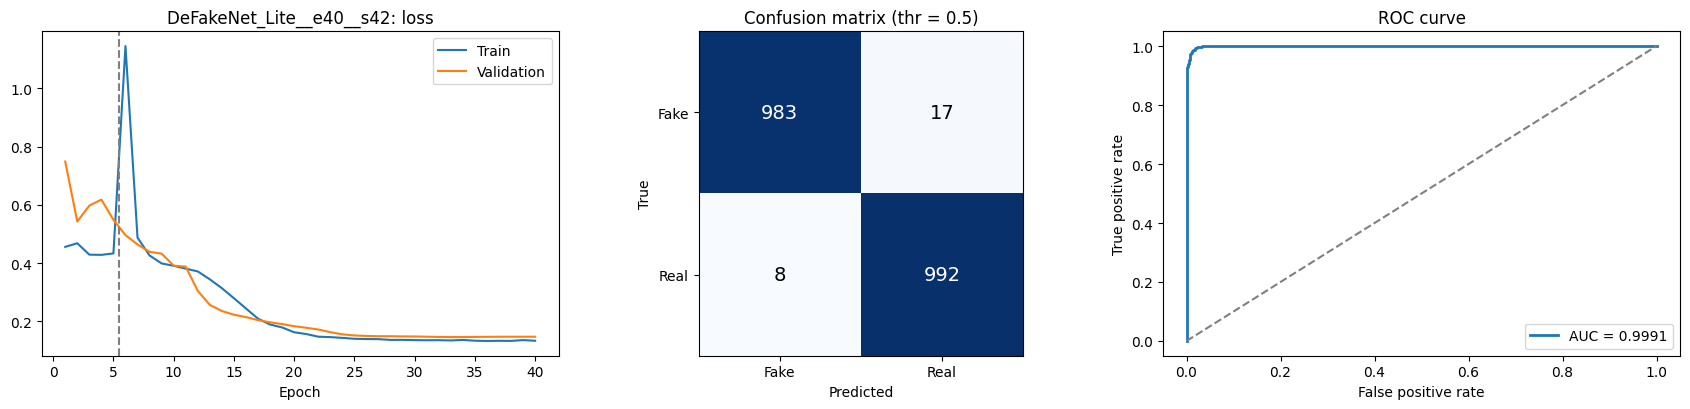

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

DeFakeNet_NR__e40__s42: 25,664,001 params | changes vs full recipe: none
Epoch 1/5
188/188 - 44s - 233ms/step - accuracy: 0.7917 - auc: 0.8762 - loss: 0.4962 - val_accuracy: 0.6450 - val_auc: 0.8206 - val_loss: 0.6427
Epoch 2/5
188/188 - 35s - 184ms/step - accuracy: 0.8115 - auc: 0.8945 - loss: 0.4540 - val_accuracy: 0.6485 - val_auc: 0.8444 - val_loss: 0.6610
Epoch 3/5
188/188 - 35s - 184ms/step - accuracy: 0.8175 - auc: 0.8995 - loss: 0.4451 - val_accuracy: 0.6155 - val_auc: 0.8439 - val_loss: 0.6746
Epoch 4/5
188/188 - 35s - 185ms/step - accuracy: 0.8295 - auc: 0.9081 - loss: 0.4342 - val_accuracy: 0.6720 - val_auc: 0.8652 - val_loss: 0.6015
Epoch 5/5
188/188 - 35s - 184ms/step - accuracy: 0.8305 - auc: 0.9126 - loss: 0.4258 - val_accuracy: 0.6890 - val_auc: 0.8636 - val_loss: 0.5967
Epoch 1/35
  EMA  val_loss 0.3983 | val_acc 0.8340 | val_auc 0.9376
188/188 - 155s - 822ms/step - accuracy: 0.6303 - auc: 0.5964 - loss: 0.9042
Epoch 

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 98.55 | AUC 99.89


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 48.70 | AUC 80.04


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 49.85 | AUC 43.79
INFO:tensorflow:Assets written to: /tmp/tmpwaz93myg/assets


INFO:tensorflow:Assets written to: /tmp/tmpwaz93myg/assets


-> DeFakeNet_NR__e40__s42: acc 98.65 | AUC 99.91 | MCC 97.31 | 25.66 M | 68.0 min | CPU b1 74 ms
              precision    recall  f1-score   support

        Fake     0.9939    0.9790    0.9864      1000
        Real     0.9793    0.9940    0.9866      1000

    accuracy                         0.9865      2000
   macro avg     0.9866    0.9865    0.9865      2000
weighted avg     0.9866    0.9865    0.9865      2000



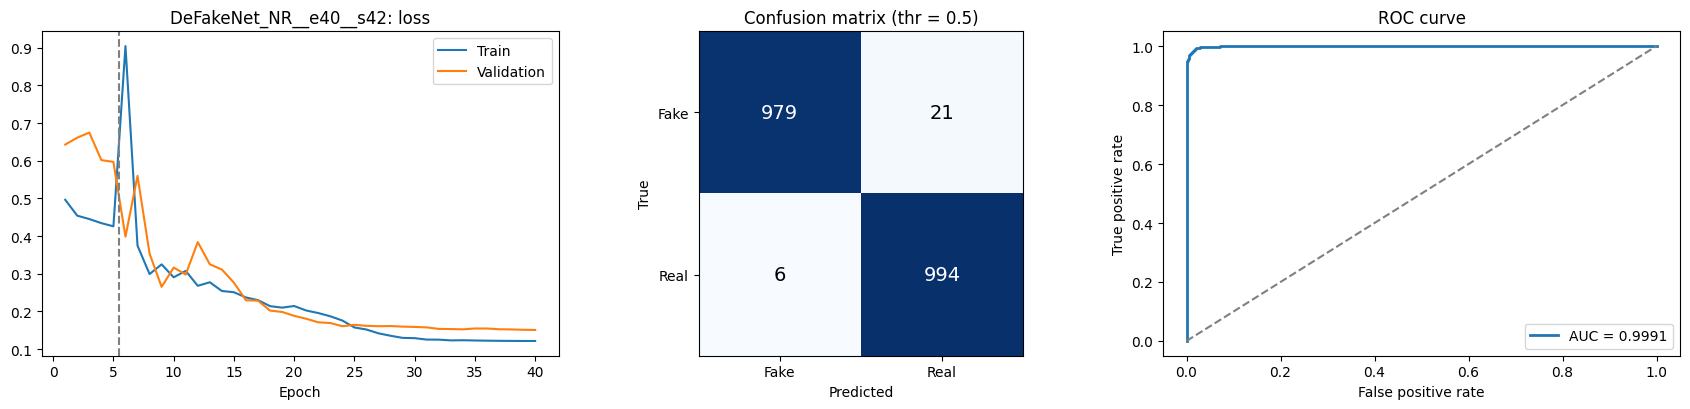

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(



DeFakeNet_Lite__e40__s1: 1,901,153 params | changes vs full recipe: none
Epoch 1/5
188/188 - 21s - 109ms/step - accuracy: 0.7898 - auc: 0.8743 - loss: 0.4778 - val_accuracy: 0.5710 - val_auc: 0.8412 - val_loss: 0.7109
Epoch 2/5
188/188 - 14s - 73ms/step - accuracy: 0.7920 - auc: 0.8778 - loss: 0.4800 - val_accuracy: 0.6785 - val_auc: 0.8580 - val_loss: 0.6059
Epoch 3/5
188/188 - 14s - 73ms/step - accuracy: 0.8133 - auc: 0.8927 - loss: 0.4584 - val_accuracy: 0.7565 - val_auc: 0.8747 - val_loss: 0.5241
Epoch 4/5
188/188 - 13s - 72ms/step - accuracy: 0.8292 - auc: 0.9085 - loss: 0.4282 - val_accuracy: 0.7030 - val_auc: 0.8836 - val_loss: 0.5668
Epoch 5/5
188/188 - 13s - 71ms/step - accuracy: 0.8355 - auc: 0.9153 - loss: 0.4188 - val_accuracy: 0.7125 - val_auc: 0.8873 - val_loss: 0.5746
Epoch 1/35
  EMA  val_loss 0.5262 | val_acc 0.7505 | val_auc 0.8798
188/188 - 88s - 469ms/step - accuracy: 0.5217 - auc: 0.4273 - loss: 1.3156
Epoch 2/35
  EMA  val_loss 0.5168 | val_acc 0.7650 | val_auc 0

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 99.05 | AUC 99.95


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 48.95 | AUC 40.81


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 52.20 | AUC 55.94
INFO:tensorflow:Assets written to: /tmp/tmps1fqrhwk/assets


INFO:tensorflow:Assets written to: /tmp/tmps1fqrhwk/assets


-> DeFakeNet_Lite__e40__s1: acc 98.80 | AUC 99.94 | MCC 97.60 | 1.90 M | 31.6 min | CPU b1 24 ms
              precision    recall  f1-score   support

        Fake     0.9900    0.9860    0.9880      1000
        Real     0.9861    0.9900    0.9880      1000

    accuracy                         0.9880      2000
   macro avg     0.9880    0.9880    0.9880      2000
weighted avg     0.9880    0.9880    0.9880      2000



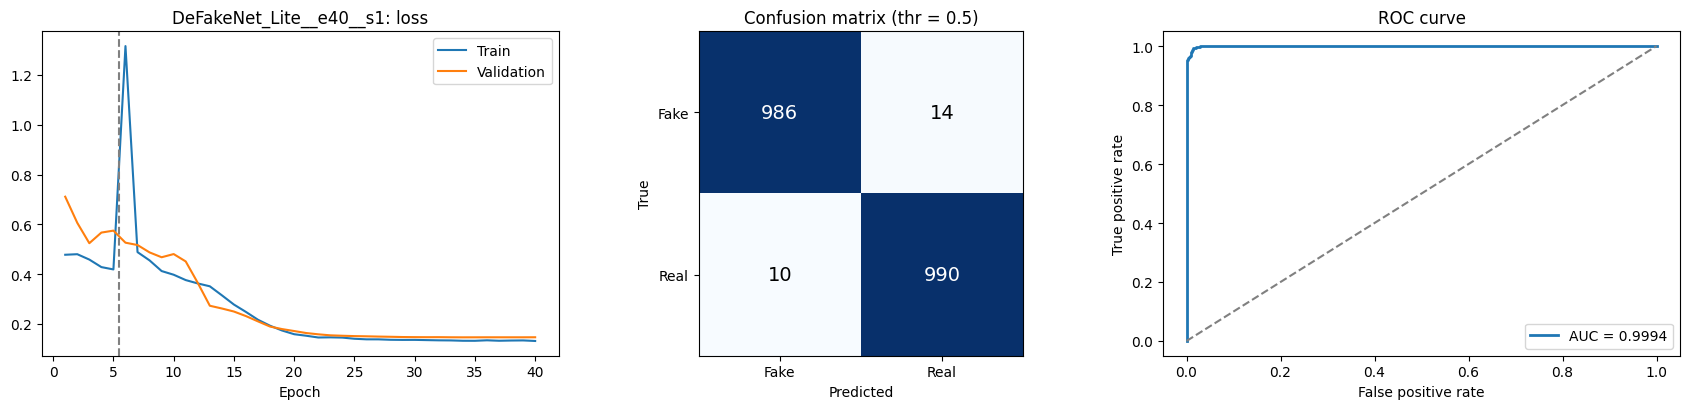


DeFakeNet_NR__e40__s1: 25,664,001 params | changes vs full recipe: none
Epoch 1/5
188/188 - 43s - 227ms/step - accuracy: 0.7822 - auc: 0.8676 - loss: 0.5260 - val_accuracy: 0.6295 - val_auc: 0.8146 - val_loss: 0.6644
Epoch 2/5
188/188 - 35s - 184ms/step - accuracy: 0.8163 - auc: 0.8958 - loss: 0.4560 - val_accuracy: 0.6585 - val_auc: 0.8421 - val_loss: 0.6102
Epoch 3/5
188/188 - 35s - 184ms/step - accuracy: 0.8183 - auc: 0.9062 - loss: 0.4360 - val_accuracy: 0.7085 - val_auc: 0.8498 - val_loss: 0.5672
Epoch 4/5
188/188 - 35s - 186ms/step - accuracy: 0.8353 - auc: 0.9186 - loss: 0.4133 - val_accuracy: 0.7310 - val_auc: 0.8563 - val_loss: 0.5473
Epoch 5/5
188/188 - 35s - 184ms/step - accuracy: 0.8367 - auc: 0.9166 - loss: 0.4165 - val_accuracy: 0.6525 - val_auc: 0.8603 - val_loss: 0.6367
Epoch 1/35
  EMA  val_loss 0.4336 | val_acc 0.8080 | val_auc 0.9397
188/188 - 148s - 786ms/step - accuracy: 0.6347 - auc: 0.6247 - loss: 0.8821
Epoch 2/35
  EMA  val_loss 0.3933 | val_acc 0.8735 | val_a

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 98.45 | AUC 99.86


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 48.80 | AUC 35.00


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 51.60 | AUC 51.48
INFO:tensorflow:Assets written to: /tmp/tmpe6bepqp2/assets


INFO:tensorflow:Assets written to: /tmp/tmpe6bepqp2/assets


-> DeFakeNet_NR__e40__s1: acc 98.10 | AUC 99.75 | MCC 96.20 | 25.66 M | 66.0 min | CPU b1 73 ms
              precision    recall  f1-score   support

        Fake     0.9829    0.9790    0.9810      1000
        Real     0.9791    0.9830    0.9810      1000

    accuracy                         0.9810      2000
   macro avg     0.9810    0.9810    0.9810      2000
weighted avg     0.9810    0.9810    0.9810      2000



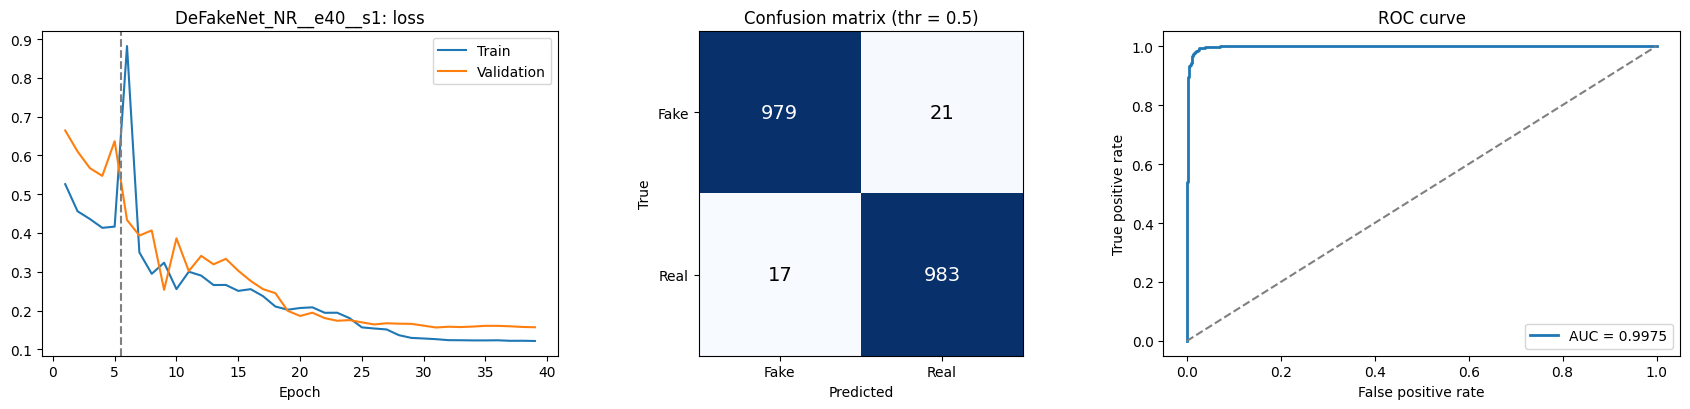

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(



DeFakeNet_Lite__e40__s2: 1,901,153 params | changes vs full recipe: none
Epoch 1/5
188/188 - 21s - 109ms/step - accuracy: 0.7982 - auc: 0.8845 - loss: 0.4606 - val_accuracy: 0.6585 - val_auc: 0.8361 - val_loss: 0.6321
Epoch 2/5
188/188 - 14s - 72ms/step - accuracy: 0.8193 - auc: 0.9001 - loss: 0.4472 - val_accuracy: 0.7055 - val_auc: 0.8603 - val_loss: 0.5765
Epoch 3/5
188/188 - 14s - 73ms/step - accuracy: 0.8337 - auc: 0.9065 - loss: 0.4385 - val_accuracy: 0.6775 - val_auc: 0.8665 - val_loss: 0.6108
Epoch 4/5
188/188 - 13s - 71ms/step - accuracy: 0.8208 - auc: 0.9037 - loss: 0.4409 - val_accuracy: 0.7400 - val_auc: 0.8710 - val_loss: 0.5425
Epoch 5/5
188/188 - 13s - 71ms/step - accuracy: 0.8275 - auc: 0.9110 - loss: 0.4284 - val_accuracy: 0.7095 - val_auc: 0.8850 - val_loss: 0.5715
Epoch 1/35
  EMA  val_loss 0.4860 | val_acc 0.7920 | val_auc 0.8929
188/188 - 85s - 455ms/step - accuracy: 0.5297 - auc: 0.4487 - loss: 1.2040
Epoch 2/35
  EMA  val_loss 0.4756 | val_acc 0.7985 | val_auc 0

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 98.95 | AUC 99.97


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 49.00 | AUC 41.69


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 54.90 | AUC 59.33
INFO:tensorflow:Assets written to: /tmp/tmpz4ab0v4h/assets


INFO:tensorflow:Assets written to: /tmp/tmpz4ab0v4h/assets


-> DeFakeNet_Lite__e40__s2: acc 98.70 | AUC 99.93 | MCC 97.41 | 1.90 M | 31.5 min | CPU b1 23 ms
              precision    recall  f1-score   support

        Fake     0.9929    0.9810    0.9869      1000
        Real     0.9812    0.9930    0.9871      1000

    accuracy                         0.9870      2000
   macro avg     0.9871    0.9870    0.9870      2000
weighted avg     0.9871    0.9870    0.9870      2000



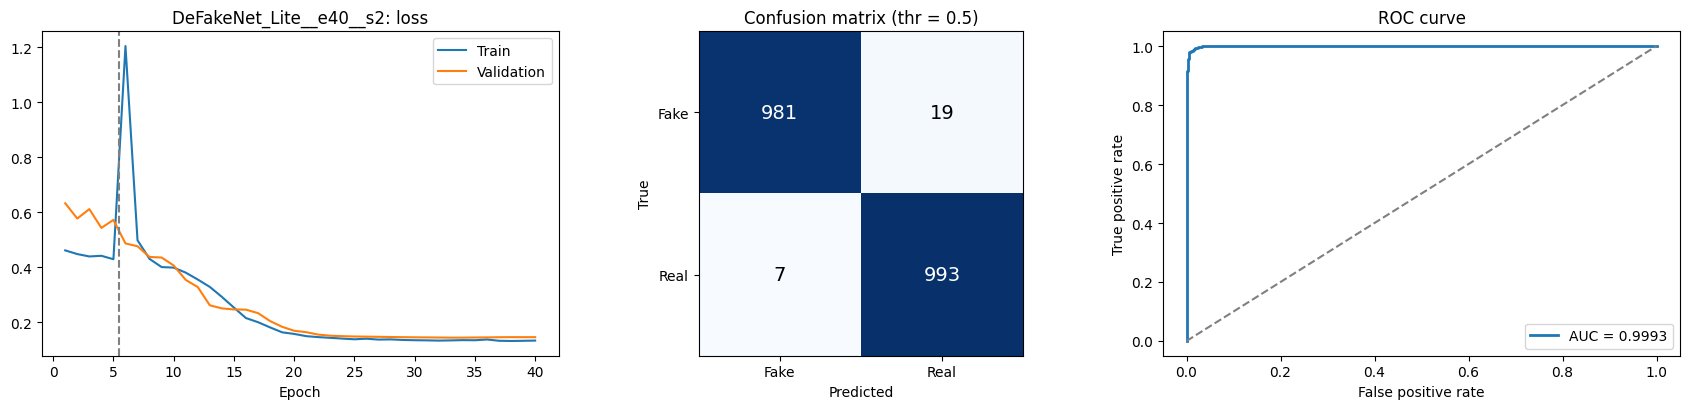


DeFakeNet_NR__e40__s2: 25,664,001 params | changes vs full recipe: none
Epoch 1/5
188/188 - 42s - 226ms/step - accuracy: 0.7927 - auc: 0.8751 - loss: 0.5092 - val_accuracy: 0.6940 - val_auc: 0.8331 - val_loss: 0.5928
Epoch 2/5
188/188 - 34s - 183ms/step - accuracy: 0.8188 - auc: 0.9033 - loss: 0.4399 - val_accuracy: 0.6565 - val_auc: 0.8373 - val_loss: 0.6720
Epoch 3/5
188/188 - 34s - 183ms/step - accuracy: 0.8270 - auc: 0.9063 - loss: 0.4363 - val_accuracy: 0.6835 - val_auc: 0.8459 - val_loss: 0.5970
Epoch 4/5
188/188 - 35s - 185ms/step - accuracy: 0.8243 - auc: 0.9089 - loss: 0.4270 - val_accuracy: 0.6515 - val_auc: 0.8538 - val_loss: 0.6521
Epoch 5/5
188/188 - 34s - 183ms/step - accuracy: 0.8387 - auc: 0.9200 - loss: 0.4139 - val_accuracy: 0.7040 - val_auc: 0.8676 - val_loss: 0.5737
Epoch 1/35
  EMA  val_loss 0.3900 | val_acc 0.8475 | val_auc 0.9316
188/188 - 145s - 773ms/step - accuracy: 0.6308 - auc: 0.5999 - loss: 0.9185
Epoch 2/35
  EMA  val_loss 0.3809 | val_acc 0.8520 | val_a

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  stylegan_140k: acc 98.05 | AUC 99.72


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  sdxl_faces: acc 49.35 | AUC 72.69


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  openforensics: acc 51.05 | AUC 46.19
INFO:tensorflow:Assets written to: /tmp/tmprwjryrtb/assets


INFO:tensorflow:Assets written to: /tmp/tmprwjryrtb/assets


-> DeFakeNet_NR__e40__s2: acc 98.75 | AUC 99.91 | MCC 97.51 | 25.66 M | 67.8 min | CPU b1 73 ms
              precision    recall  f1-score   support

        Fake     0.9939    0.9810    0.9874      1000
        Real     0.9812    0.9940    0.9876      1000

    accuracy                         0.9875      2000
   macro avg     0.9876    0.9875    0.9875      2000
weighted avg     0.9876    0.9875    0.9875      2000



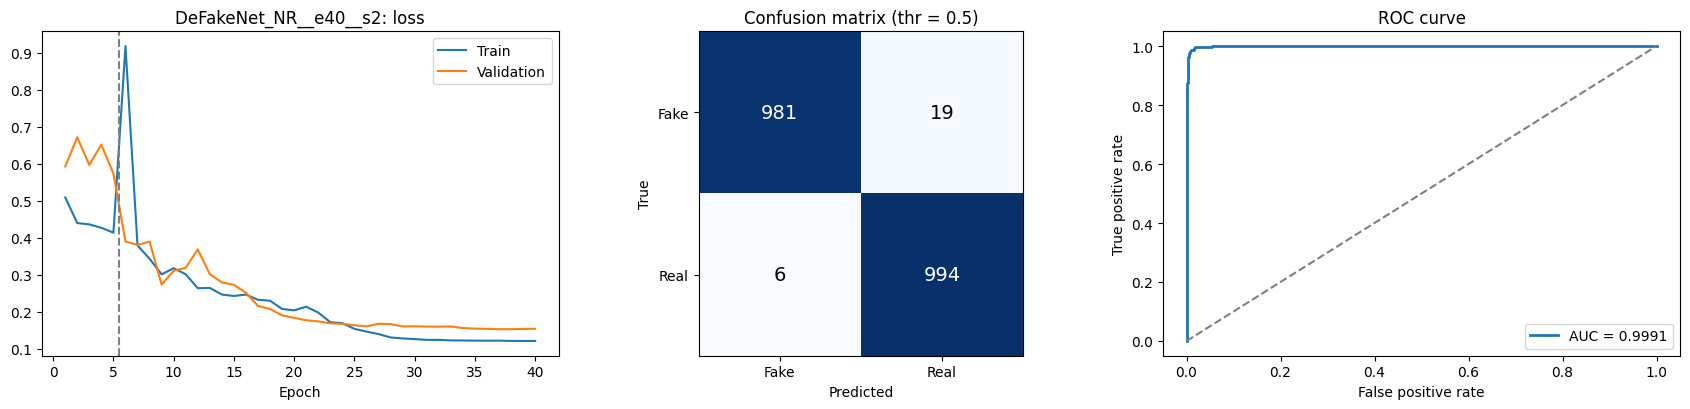

finished runs: 6 of 6


In [9]:
TAG = "e40"   # 40-epoch runs of this notebook (keeps them apart from the 30-epoch runs of notebook 02)
RUNS = []     # (group, model, tag, seed)
RUNS += [("main", PROPOSED, TAG, SEEDS[0]), ("main", BASELINE, TAG, SEEDS[0])]
RUNS += [("seeds", m, TAG, s) for s in SEEDS[1:] for m in (PROPOSED, BASELINE)]
RUNS = [r for r in RUNS if r[0] in RUN_GROUPS]
print(len(RUNS), "runs:")
for g, n, t, s in RUNS: print(f"  {g:6s} {PRETTY[n]:26s} seed {s}")

RESULTS = {}
for g, n, t, s in RUNS:
    key = f"{n}__{t}__s{s}"; path = f"{OUTDIR}/{key}_results.json"
    try:
        if os.path.exists(path):
            RESULTS[key] = json.load(open(path)); print("loaded", key)
        else:
            RESULTS[key] = run_experiment(n, t, s, {}, g)
        show_report(RESULTS[key])
    except Exception as e:
        import traceback; traceback.print_exc()
        print(f"!! {key} FAILED: {e!r}")
print("finished runs:", len(RESULTS), "of", len(RUNS))

## 10. Results

### 10.0 All runs of this notebook in one table

In [10]:
PAPER = dict(acc=91.95, auc=97.64, pr_auc=97.40, mcc=83.95, f1=91.81, precision=93.47, recall_real=90.20,
             tn=937, tp=902, params=25_664_001)        # Samal et al. 2025, as reported (Real = positive class)
from scipy.stats import binomtest

def probs(key):   # test scores of a run: this notebook first, else notebook 02
    return np.load(f"{OUTDIR}/{key}_probs.npz" if key in RESULTS else PREV_PROBS[key])["p_test"]

def mcnemar(k1, k2):
    # exact McNemar test on the same 2,000 test images: only the images where the two models disagree count
    c1 = (probs(k1) >= 0.5).astype(int) == y_test
    c2 = (probs(k2) >= 0.5).astype(int) == y_test
    only1, only2 = int((c1 & ~c2).sum()), int((~c1 & c2).sum())
    p = binomtest(min(only1, only2), only1 + only2, 0.5).pvalue if only1 + only2 else 1.0
    return only1, only2, p

def keys(model, tag=TAG, src=None):
    src = RESULTS if src is None else src
    return sorted([k for k in src if src[k]["model"] == model and src[k]["tag"] == tag], key=lambda k: src[k]["seed"])

pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
rows = []
for k, r in RESULTS.items():
    m = r["test"]["thr=0.5"]
    rows.append({"Run": k, "Model": PRETTY[r["model"]], "Seed": r["seed"], "Params (M)": r["params"]/1e6,
                 "GMACs": r["gmacs"], "Acc %": m["acc"], "AUC %": m["auc"], "PR-AUC %": m["pr_auc"], "MCC %": m["mcc"],
                 "F1 %": m["f1"], "Precision %": m["precision"], "Recall (real) %": m["recall_real"],
                 "Specificity (fake) %": m["specificity"], "Fakes caught /1000": m["tn"], "Reals caught /1000": m["tp"],
                 "TFLite fp16 MB": r["tflite_mb"], "GPU ms/img b32": r["gpu_ms_b32"], "CPU ms/img b1": r["cpu_ms_b1"],
                 "Train min": r["train_min"], "Epochs run": r["epochs_run"], "Best FT epoch": r.get("best_ft_epoch")})
ALL = pd.DataFrame(rows).set_index("Run")
display(ALL.round(2)); ALL.round(3).to_csv(f"{OUTDIR}/all_runs.csv")

,Model,Seed,Params (M),GMACs,Acc %,AUC %,PR-AUC %,MCC %,F1 %,Precision %,Recall (real) %,Specificity (fake) %,Fakes caught /1000,Reals caught /1000,TFLite fp16 MB,GPU ms/img b32,CPU ms/img b1,Train min,Epochs run,Best FT epoch
Run,,,,,,,,,,,,,,,,,,,,
DeFakeNet_Lite__e40__s42,DeFakeNet-Lite (ours),42,1.90,0.21,98.75,99.91,99.91,97.50,98.76,98.32,99.2,98.3,983,992,3.87,1.42,25.54,31.85,40,28
DeFakeNet_NR__e40__s42,DeFakeNet + our recipe,42,25.66,4.57,98.65,99.91,99.91,97.31,98.66,97.93,99.4,97.9,979,994,51.32,3.96,74.46,68.05,40,35
DeFakeNet_Lite__e40__s1,DeFakeNet-Lite (ours),1,1.90,0.21,98.80,99.94,99.94,97.60,98.80,98.61,99.0,98.6,986,990,3.87,1.38,24.21,31.65,40,29
DeFakeNet_NR__e40__s1,DeFakeNet + our recipe,1,25.66,4.57,98.10,99.75,99.63,96.20,98.10,97.91,98.3,97.9,979,983,51.32,3.97,73.04,65.96,39,26
DeFakeNet_Lite__e40__s2,DeFakeNet-Lite (ours),2,1.90,0.21,98.70,99.93,99.93,97.41,98.71,98.12,99.3,98.1,981,993,3.87,1.37,22.81,31.52,40,28
DeFakeNet_NR__e40__s2,DeFakeNet + our recipe,2,25.66,4.57,98.75,99.91,99.90,97.51,98.76,98.12,99.4,98.1,981,994,51.32,3.96,72.84,67.75,40,32


### 10.1 Main result: mean ± std over 3 seeds (RQ1 and RQ2)

A **seed** fixes the random choices in training (starting weights of the head, image order, random augmentation). Three seeds show the result is not luck; a small ± means a stable model. The first row is the base paper's own reported result.

In [11]:
fmt = lambda x: f"{np.mean(x):.2f} ± {np.std(x, ddof=1):.2f}" if len(x) > 1 else f"{x[0]:.2f}"
rows = [{"Model": "DeFakeNet (paper, reported)", "Params (M)": 25.66, "Epochs": "≤40", "Seeds": "1 run",
         "Acc %": f"{PAPER['acc']:.2f}", "AUC %": f"{PAPER['auc']:.2f}", "PR-AUC %": f"{PAPER['pr_auc']:.2f}",
         "MCC %": f"{PAPER['mcc']:.2f}", "F1 %": f"{PAPER['f1']:.2f}"}]
SEED_VALS = {}
for name in (BASELINE, PROPOSED):
    ks = keys(name)
    if not ks: continue
    v = {c: [RESULTS[k]["test"]["thr=0.5"][c] for k in ks] for c in ("acc", "auc", "pr_auc", "mcc", "f1")}
    SEED_VALS[name] = v
    rows.append({"Model": PRETTY[name], "Params (M)": round(RESULTS[ks[0]]["params"] / 1e6, 2), "Epochs": "40",
                 "Seeds": ", ".join(str(RESULTS[k]["seed"]) for k in ks), "Acc %": fmt(v["acc"]), "AUC %": fmt(v["auc"]),
                 "PR-AUC %": fmt(v["pr_auc"]), "MCC %": fmt(v["mcc"]), "F1 %": fmt(v["f1"])})
MAIN_T = pd.DataFrame(rows).set_index("Model")
display(MAIN_T); MAIN_T.to_csv(f"{OUTDIR}/table_main_results.csv")
for name in SEED_VALS:
    print(f"{PRETTY[name]}: {np.mean(SEED_VALS[name]['acc']) - PAPER['acc']:+.2f} pt accuracy over the paper's reported {PAPER['acc']}%")

print("\nMcNemar test, DeFakeNet-Lite vs DeFakeNet + our recipe, same seed (p < 0.05 = a real difference, not luck):")
MCN = []
for kp in keys(PROPOSED):
    kb = next((k for k in keys(BASELINE) if RESULTS[k]["seed"] == RESULTS[kp]["seed"]), None)
    if kb is None: continue
    o1, o2, p = mcnemar(kp, kb); MCN.append(p)
    print(f"  seed {RESULTS[kp]['seed']:>2}: Lite {RESULTS[kp]['test']['thr=0.5']['acc']:.2f} vs DeFakeNet "
          f"{RESULTS[kb]['test']['thr=0.5']['acc']:.2f} | only Lite right {o1}, only DeFakeNet right {o2} | p = {p:.3f}")

,Params (M),Epochs,Seeds,Acc %,AUC %,PR-AUC %,MCC %,F1 %
Model,,,,,,,,
"DeFakeNet (paper, reported)",25.66,≤40,1 run,91.95,97.64,97.40,83.95,91.81
DeFakeNet + our recipe,25.66,40,"1, 2, 42",98.50 ± 0.35,99.85 ± 0.09,99.82 ± 0.16,97.01 ± 0.70,98.51 ± 0.35
DeFakeNet-Lite (ours),1.90,40,"1, 2, 42",98.75 ± 0.05,99.93 ± 0.01,99.93 ± 0.01,97.50 ± 0.10,98.76 ± 0.05


DeFakeNet + our recipe: +6.55 pt accuracy over the paper's reported 91.95%
DeFakeNet-Lite (ours): +6.80 pt accuracy over the paper's reported 91.95%

McNemar test, DeFakeNet-Lite vs DeFakeNet + our recipe, same seed (p < 0.05 = a real difference, not luck):
  seed  1: Lite 98.80 vs DeFakeNet 98.10 | only Lite right 33, only DeFakeNet right 19 | p = 0.070
  seed  2: Lite 98.70 vs DeFakeNet 98.75 | only Lite right 23, only DeFakeNet right 24 | p = 1.000
  seed 42: Lite 98.75 vs DeFakeNet 98.65 | only Lite right 23, only DeFakeNet right 21 | p = 0.880


### 10.2 Is it really lightweight? Same machine, same session (RQ2)

Averaged over the seeds of each model (cost does not depend on the seed; speed is averaged to reduce timing noise).

In [12]:
def cost(name):
    ks = keys(name)
    return [np.mean([RESULTS[k][c] for k in ks if RESULTS[k][c] is not None]) if any(RESULTS[k][c] is not None for k in ks) else np.nan
            for c in ("params", "gmacs", "tflite_mb", "cpu_ms_b1", "gpu_ms_b32", "train_min")]
COST = None
if keys(PROPOSED) and keys(BASELINE):
    COST = pd.DataFrame({PRETTY[BASELINE]: cost(BASELINE), PRETTY[PROPOSED]: cost(PROPOSED)},
                        index=["Parameters", "GMACs per image", "TFLite fp16 size (MB)", "CPU ms per image (batch 1)",
                               "GPU ms per image (batch 32)", "Training time (min)"])
    COST.loc["Parameters"] /= 1e6; COST = COST.rename(index={"Parameters": "Parameters (M)"})
    COST["DeFakeNet ÷ Lite (x)"] = COST.iloc[:, 0] / COST.iloc[:, 1]
    display(COST.round(2)); COST.round(3).to_csv(f"{OUTDIR}/table_cost_same_machine.csv")

,DeFakeNet + our recipe,DeFakeNet-Lite (ours),DeFakeNet ÷ Lite (x)
Parameters (M),25.66,1.90,13.50
GMACs per image,4.57,0.21,22.00
TFLite fp16 size (MB),51.32,3.87,13.27
CPU ms per image (batch 1),73.45,24.18,3.04
GPU ms per image (batch 32),3.96,1.39,2.85
Training time (min),67.25,31.67,2.12


### 10.3 Ablation: which part of the recipe matters? (RQ1, reused from notebook 02)

DeFakeNet-Lite, seed 42, 30 epochs, all 8 runs from the same session of notebook 02. Each row switches **one** part back to the DeFakeNet paper's way. Δ < 0 means the model got worse without that part; McNemar p < 0.05 means the change is unlikely to be luck. These are single runs, so a change smaller than about the seed spread (±0.1–0.4 points) is noise.

In [13]:
ref = PREV[ABL_REF]["test"]["thr=0.5"]
rows = [{"Switched back to the paper's way": "nothing (full recipe)", "Acc %": ref["acc"], "AUC %": ref["auc"],
         "MCC %": ref["mcc"], "Δ Acc (pt)": 0.0, "Δ AUC (pt)": 0.0, "only full right / only ablated right": "-", "McNemar p": np.nan}]
for t, desc in ABL_TAGS.items():
    k = f"{PREV_LITE}__{t}__s42"
    m = PREV[k]["test"]["thr=0.5"]; o1, o2, p = mcnemar(ABL_REF, k)
    rows.append({"Switched back to the paper's way": desc, "Acc %": m["acc"], "AUC %": m["auc"], "MCC %": m["mcc"],
                 "Δ Acc (pt)": m["acc"] - ref["acc"], "Δ AUC (pt)": m["auc"] - ref["auc"],
                 "only full right / only ablated right": f"{o1} / {o2}", "McNemar p": p})
ABL = pd.DataFrame(rows).set_index("Switched back to the paper's way")
ABL = pd.concat([ABL.iloc[:1], ABL.iloc[1:].sort_values("Δ Acc (pt)")])
display(ABL.round(3)); ABL.round(4).to_csv(f"{OUTDIR}/table_ablation.csv")

,Acc %,AUC %,MCC %,Δ Acc (pt),Δ AUC (pt),only full right / only ablated right,McNemar p
Switched back to the paper's way,,,,,,,
nothing (full recipe),98.45,99.870,96.900,0.00,0.000,-,NaN
"old heavy augmentation (rotate, 20% shift, zoom, upside-down flips)",94.60,98.885,89.218,-3.85,-0.985,92 / 15,0.000
images shrunk to 224 x 224,98.00,99.665,96.001,-0.45,-0.205,25 / 16,0.211
BatchNorm not frozen,98.25,99.821,96.501,-0.20,-0.049,11 / 7,0.481
no EMA weight averaging,98.50,99.898,97.003,0.05,0.028,10 / 11,1.000
no label smoothing,98.60,99.896,97.201,0.15,0.026,10 / 13,0.678
no frozen warm-up (30 epochs of full fine-tuning),99.05,99.964,98.108,0.60,0.094,11 / 23,0.058
plain Adam with a constant learning rate,99.05,99.962,98.106,0.60,0.092,5 / 17,0.017


### 10.4 Is the paper's 0-to-1 pixel scaling the problem? (RQ1, reused from notebook 02)

Same DeFakeNet model and our recipe (30 epochs); the only change is the pixel scale fed to ResNet50V2 (the paper used 0–1, ResNet50V2 was pre-trained with −1 to 1).

In [14]:
m01 = PREV[K01]["test"]["thr=0.5"]
same = keys(BASELINE, "full", PREV)          # DeFakeNet + our recipe, -1..1 input, 30 epochs (notebook 02)
full = [PREV[k]["test"]["thr=0.5"]["acc"] for k in same]
SCALE_T = pd.DataFrame([
    {"Input scaling": "0..1 (the paper's)", "Seeds": "42", "Acc %": f"{m01['acc']:.2f}", "AUC %": f"{m01['auc']:.2f}", "MCC %": f"{m01['mcc']:.2f}"},
    {"Input scaling": "-1..1 (what ResNet50V2 expects)", "Seeds": ", ".join(str(PREV[k]["seed"]) for k in same),
     "Acc %": fmt(full), "AUC %": fmt([PREV[k]["test"]["thr=0.5"]["auc"] for k in same]),
     "MCC %": fmt([PREV[k]["test"]["thr=0.5"]["mcc"] for k in same])}]).set_index("Input scaling")
display(SCALE_T); SCALE_T.to_csv(f"{OUTDIR}/table_paper_scaling.csv")
print(f"-> effect of the 0..1 scaling alone: {m01['acc'] - np.mean(full):+.2f} pt accuracy (inside the seed spread = no real effect)")

,Seeds,Acc %,AUC %,MCC %
Input scaling,,,,
0..1 (the paper's),42,98.40,99.83,96.80
-1..1 (what ResNet50V2 expects),"1, 2",98.53 ± 0.25,99.86 ± 0.02,97.05 ± 0.49


-> effect of the 0..1 scaling alone: -0.12 pt accuracy (inside the seed spread = no real effect)


### 10.5 Cross-dataset test: trained on RVF10K only, no retraining (RQ3)

**AUC** is the fairest number here: it does not depend on the 0.5 threshold, which often shifts on a new dataset. AUC ≈ 50 means guessing. These are zero-shot numbers, so they are **not** comparable with papers that trained on these datasets.

In [15]:
XD = XAGG = None
if EXTERNAL:
    rows = []
    for k, r in RESULTS.items():
        row = {"Run": k, "Model": r["model"], "RVF10K Acc %": r["test"]["thr=0.5"]["acc"], "RVF10K AUC %": r["test"]["thr=0.5"]["auc"]}
        for en, m in r["external"].items():
            row[f"{en} | Acc %"] = m["acc"]; row[f"{en} | AUC %"] = m["auc"]
        rows.append(row)
    XD = pd.DataFrame(rows).set_index("Run")
    display(XD.round(2)); XD.round(3).to_csv(f"{OUTDIR}/table_cross_dataset_per_run.csv")
    XAGG = XD.groupby("Model").agg(["mean", "std"])
    XAGG.index = [PRETTY[i] for i in XAGG.index]
    print("Mean and std over seeds:"); display(XAGG.round(2)); XAGG.round(3).to_csv(f"{OUTDIR}/table_cross_dataset_mean.csv")
else:
    print("No extra datasets were available, so there is no cross-dataset result.")

,Model,RVF10K Acc %,RVF10K AUC %,stylegan_140k | Acc %,stylegan_140k | AUC %,sdxl_faces | Acc %,sdxl_faces | AUC %,openforensics | Acc %,openforensics | AUC %
Run,,,,,,,,,
DeFakeNet_Lite__e40__s42,DeFakeNet_Lite,98.75,99.91,98.90,99.95,48.75,46.15,54.00,58.56
DeFakeNet_NR__e40__s42,DeFakeNet_NR,98.65,99.91,98.55,99.89,48.70,80.04,49.85,43.79
DeFakeNet_Lite__e40__s1,DeFakeNet_Lite,98.80,99.94,99.05,99.95,48.95,40.81,52.20,55.94
DeFakeNet_NR__e40__s1,DeFakeNet_NR,98.10,99.75,98.45,99.86,48.80,35.00,51.60,51.48
DeFakeNet_Lite__e40__s2,DeFakeNet_Lite,98.70,99.93,98.95,99.97,49.00,41.69,54.90,59.33
DeFakeNet_NR__e40__s2,DeFakeNet_NR,98.75,99.91,98.05,99.72,49.35,72.69,51.05,46.19


Mean and std over seeds:


RVF10K Acc %       RVF10K AUC %       stylegan_140k | Acc %       stylegan_140k | AUC %       sdxl_faces | Acc %       sdxl_faces | AUC %        openforensics | Acc %       openforensics | AUC %      
                               mean   std         mean   std                  mean   std                  mean   std               mean   std               mean    std                  mean   std                  mean   std
DeFakeNet-Lite (ours)         98.75  0.05        99.93  0.01                 98.97  0.08                 99.96  0.01              48.90  0.13              42.88   2.86                 53.70  1.37                 57.94  1.77
DeFakeNet + our recipe        98.50  0.35        99.85  0.09                 98.35  0.26                 99.82  0.09              48.95  0.35              62.58  24.16                 50.83  0.89                 47.15  3.94

## 11. Figures

Every figure is saved as a 300-dpi PNG in `figures/` (and in `thesis_results.zip`).

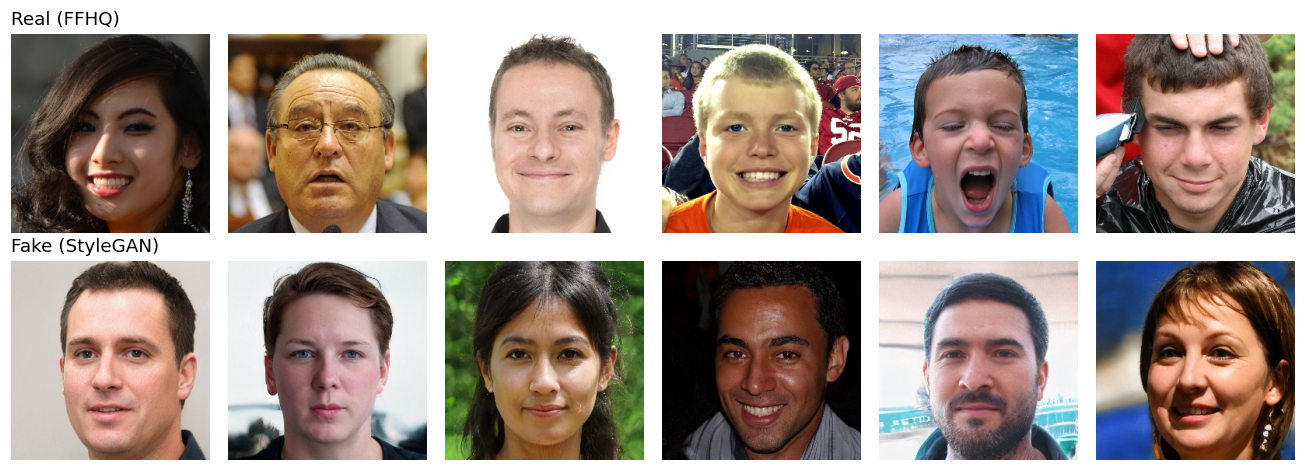

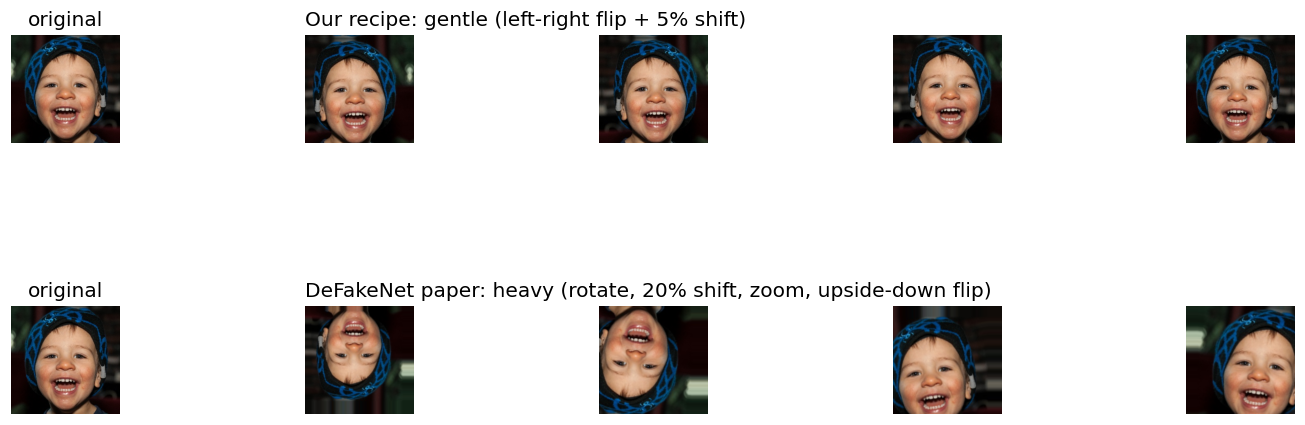

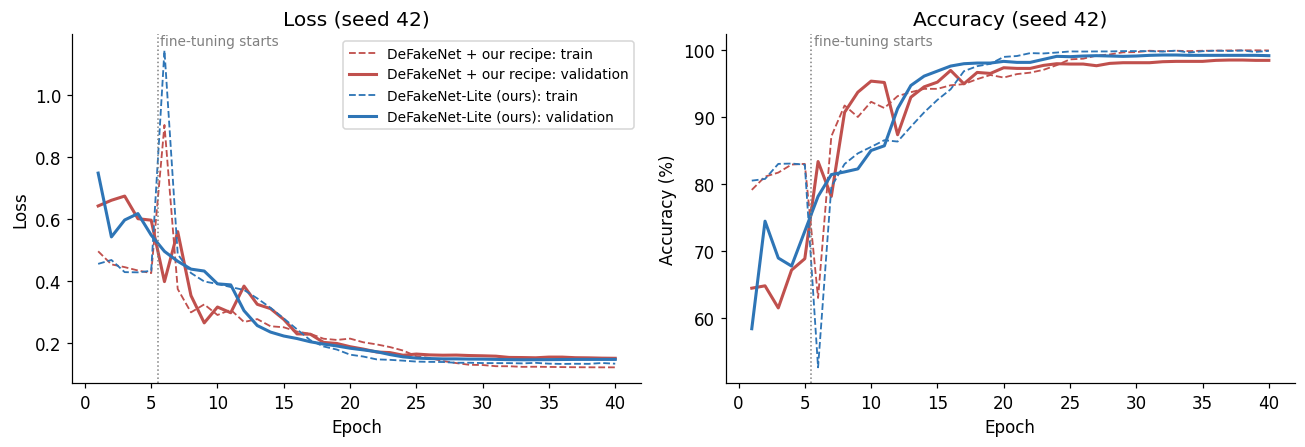

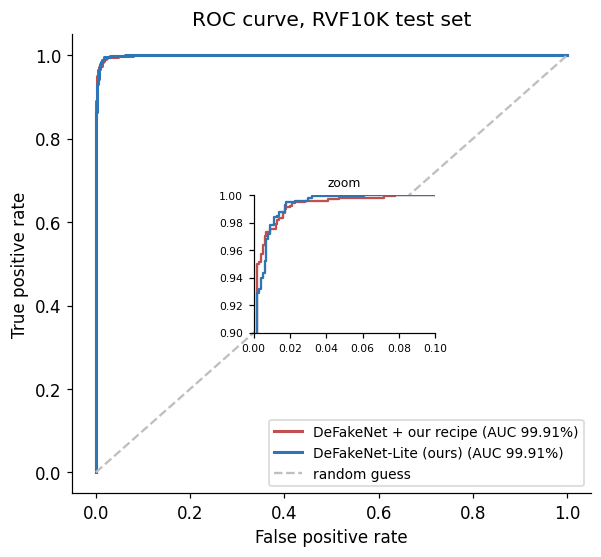

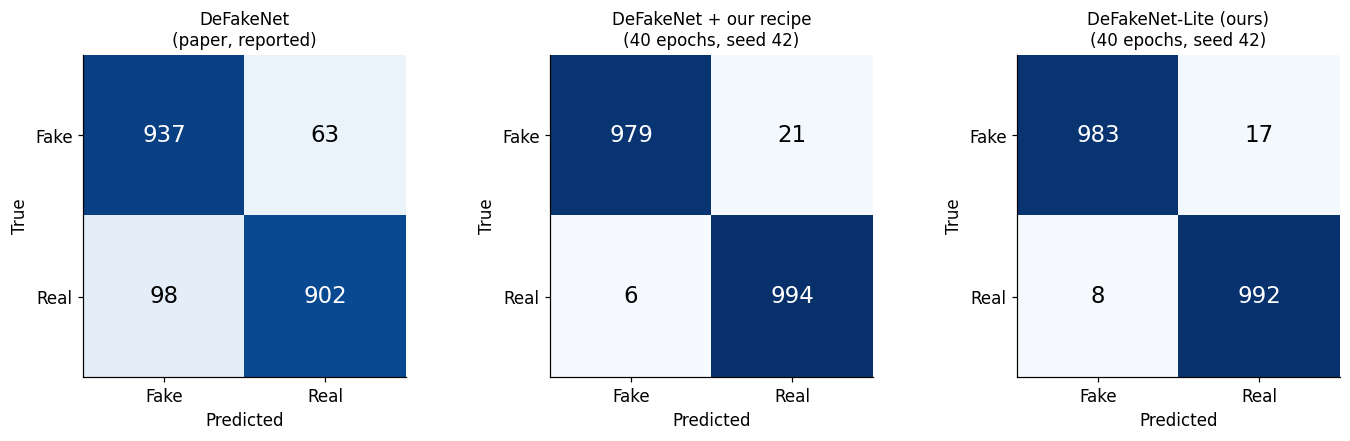

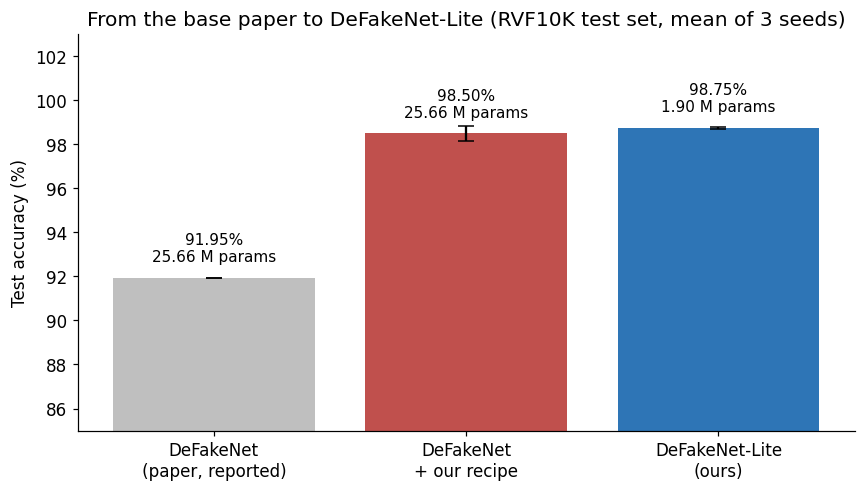

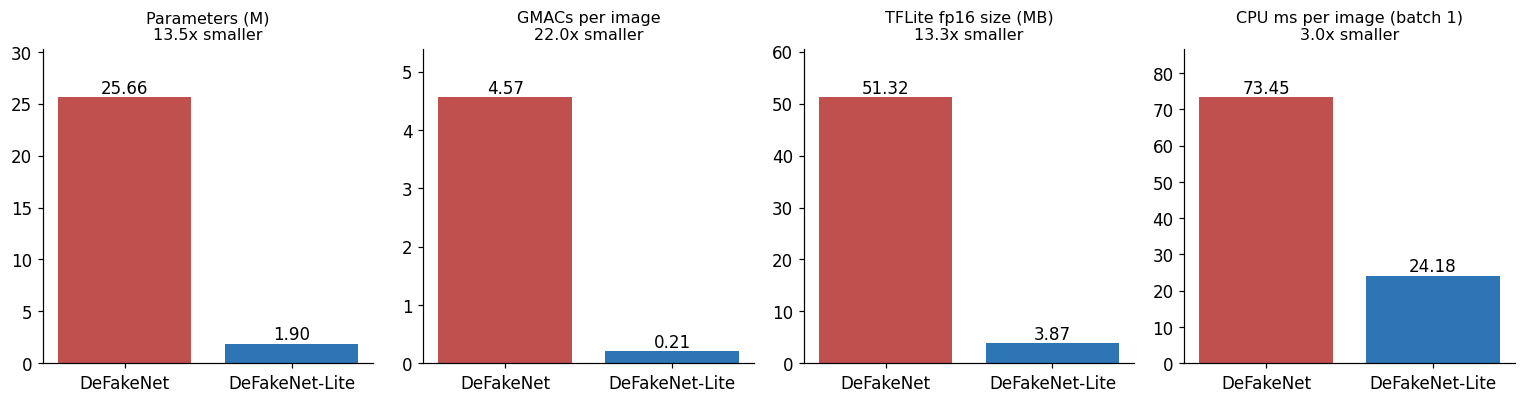

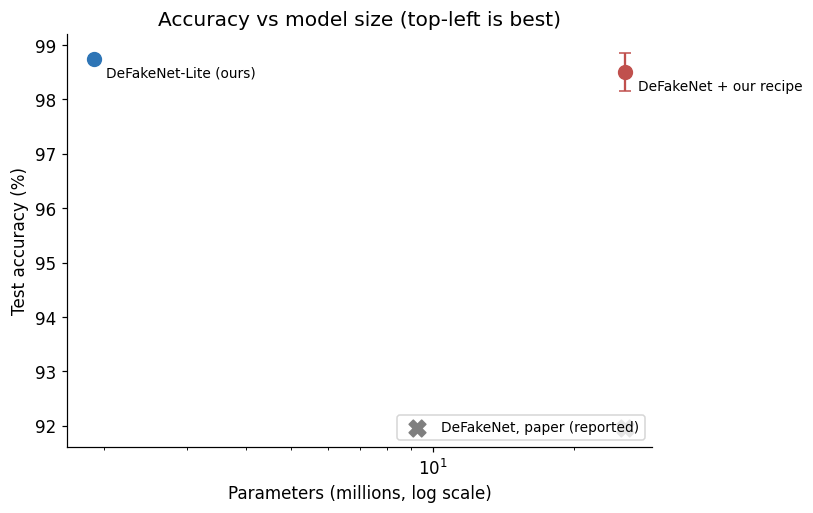

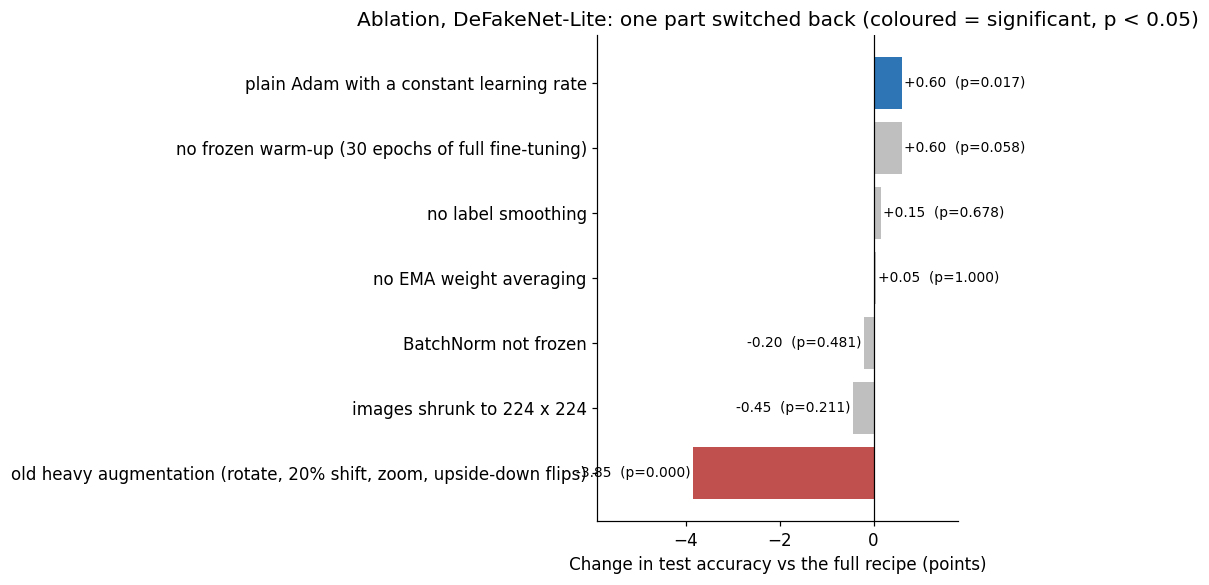

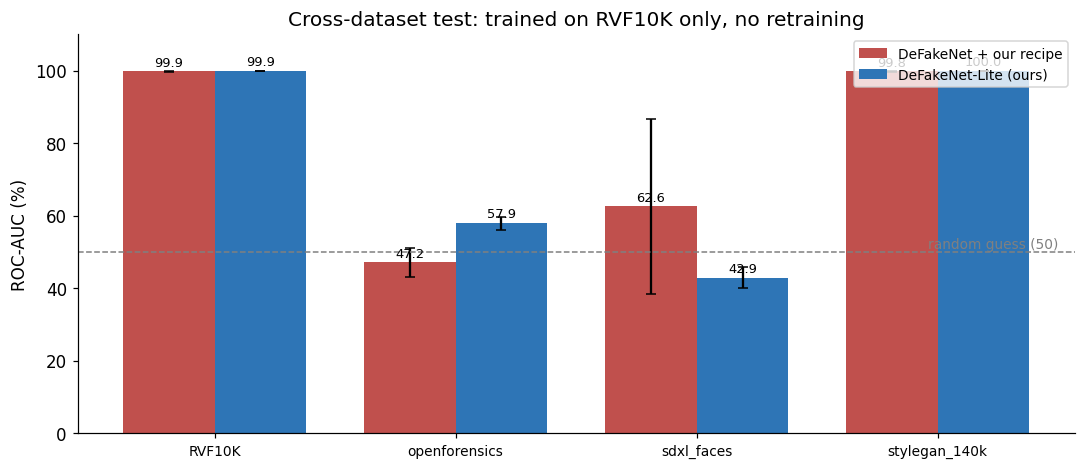

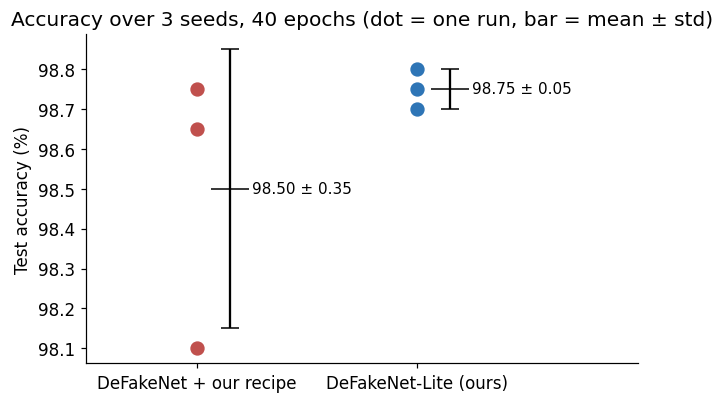

figures: ['F01_dataset_samples.png', 'F02_augmentation_gentle_vs_heavy.png', 'F03_training_curves.png', 'F04_roc_curves.png', 'F05_confusion_matrices.png', 'F06_accuracy_journey.png', 'F07_cost_comparison.png', 'F08_accuracy_vs_params.png', 'F09_ablation.png', 'F10_cross_dataset_auc.png', 'F11_seed_stability.png']


In [16]:
FIG = f"{OUTDIR}/figures"; os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
C_BASE, C_PROP, C_OLD, C_GREY = "#C0504D", "#2E75B6", "#7F7F7F", "#BFBFBF"
def save(fig, name):
    fig.tight_layout(); fig.savefig(f"{FIG}/{name}.png", bbox_inches="tight"); plt.show(); plt.close(fig)
def safe(fn):
    try: fn()
    except Exception as e: print(f"  figure {fn.__name__} skipped: {e!r}")

def f01_dataset_samples():   # sample real and fake test images
    fig, ax = plt.subplots(2, 6, figsize=(12, 4.4))
    for row, cls in enumerate(("real", "fake")):
        files = list_images(os.path.join(TEST_DIR, cls)); random.Random(7).shuffle(files)
        for j in range(6):
            ax[row, j].imshow(Image.open(files[j]).convert("RGB")); ax[row, j].axis("off")
        ax[row, 0].set_title(("Real (FFHQ)" if cls == "real" else "Fake (StyleGAN)"), loc="left", fontsize=12)
    save(fig, "F01_dataset_samples")

def f02_augmentation():      # gentle (new) vs heavy (old) augmentation on the same face
    img = np.array(Image.open(list_images(os.path.join(TRAIN_DIR, "real"))[3]).convert("RGB").resize((NATIVE, NATIVE)), np.float32)
    fig, ax = plt.subplots(2, 5, figsize=(12, 5.2))
    for row, kind in enumerate(("gentle", "heavy")):
        aug = keras.Sequential(augment_layers(kind)); keras.utils.set_random_seed(3)
        ax[row, 0].imshow(img.astype(np.uint8)); ax[row, 0].set_title("original")
        for j in range(1, 5):
            ax[row, j].imshow(np.clip(aug(img[None], training=True)[0].numpy(), 0, 255).astype(np.uint8))
        for a in ax[row]: a.axis("off")
        ax[row, 1].set_title(("Our recipe: gentle (left-right flip + 5% shift)" if kind == "gentle"
                              else "DeFakeNet paper: heavy (rotate, 20% shift, zoom, upside-down flip)"), loc="left")
    save(fig, "F02_augmentation_gentle_vs_heavy")

def f03_training_curves():   # loss + accuracy, DeFakeNet vs proposed, seed 42
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    for name, col in ((BASELINE, C_BASE), (PROPOSED, C_PROP)):
        k = f"{name}__{TAG}__s{SEEDS[0]}"
        if k not in RESULTS: continue
        h = RESULTS[k]["history"]; ep = np.arange(1, len(h["loss"]) + 1)
        ax[0].plot(ep, h["loss"], c=col, ls="--", lw=1.2, label=f"{PRETTY[name]}: train")
        ax[0].plot(ep, h["val_loss"], c=col, lw=2, label=f"{PRETTY[name]}: validation")
        ax[1].plot(ep, np.array(h["accuracy"]) * 100, c=col, ls="--", lw=1.2)
        ax[1].plot(ep, np.array(h["val_accuracy"]) * 100, c=col, lw=2)
    for a in ax:
        a.axvline(BASE_CFG["warmup"] + 0.5, c="gray", ls=":", lw=1); a.set_xlabel("Epoch")
        a.text(BASE_CFG["warmup"] + 0.7, a.get_ylim()[1], "fine-tuning starts", va="top", fontsize=9, color="gray")
    ax[0].set_ylabel("Loss"); ax[0].set_title("Loss (seed 42)"); ax[1].set_ylabel("Accuracy (%)"); ax[1].set_title("Accuracy (seed 42)")
    ax[0].legend(fontsize=9)
    save(fig, "F03_training_curves")

def f04_roc():               # ROC on the RVF10K test set, seed 42
    fig, ax = plt.subplots(figsize=(5.6, 5.2))
    for name, col in ((BASELINE, C_BASE), (PROPOSED, C_PROP)):
        k = f"{name}__{TAG}__s{SEEDS[0]}"
        if k not in RESULTS: continue
        p = probs(k); f, t, _ = roc_curve(y_test, p)
        ax.plot(f, t, c=col, lw=2, label=f"{PRETTY[name]} (AUC {auc(f, t)*100:.2f}%)")
    ax.plot([0, 1], [0, 1], "--", c=C_GREY, label="random guess")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title("ROC curve, RVF10K test set")
    ax.legend(loc="lower right", fontsize=9)
    ins = ax.inset_axes([0.35, 0.35, 0.35, 0.3])   # zoom on the top-left corner
    for name, col in ((BASELINE, C_BASE), (PROPOSED, C_PROP)):
        k = f"{name}__{TAG}__s{SEEDS[0]}"
        if k in RESULTS:
            f, t, _ = roc_curve(y_test, probs(k)); ins.plot(f, t, c=col, lw=1.5)
    ins.set_xlim(0, 0.1); ins.set_ylim(0.9, 1.0); ins.set_title("zoom", fontsize=8); ins.tick_params(labelsize=7)
    save(fig, "F04_roc_curves")

def f05_confusion():         # confusion matrices, seed 42, + the paper's reported matrix for contrast
    mats = [("DeFakeNet\n(paper, reported)", np.array([[PAPER["tn"], 1000 - PAPER["tn"]], [1000 - PAPER["tp"], PAPER["tp"]]]))]
    for name in (BASELINE, PROPOSED):
        k = f"{name}__{TAG}__s{SEEDS[0]}"
        if k in RESULTS:
            m = RESULTS[k]["test"]["thr=0.5"]; mats.append((PRETTY[name] + "\n(40 epochs, seed 42)", np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])))
    fig, ax = plt.subplots(1, len(mats), figsize=(4.3 * len(mats), 4))
    for a, (title, cm) in zip(np.atleast_1d(ax), mats):
        a.imshow(cm, cmap="Blues", vmin=0, vmax=1000)
        for i in range(2):
            for j in range(2):
                a.text(j, i, cm[i, j], ha="center", va="center", fontsize=15, color="white" if cm[i, j] > 500 else "black")
        a.set_xticks([0, 1]); a.set_xticklabels(["Fake", "Real"]); a.set_yticks([0, 1]); a.set_yticklabels(["Fake", "Real"])
        a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(title, fontsize=11)
    save(fig, "F05_confusion_matrices")

def f06_journey():           # accuracy: base paper -> our recipe -> DeFakeNet-Lite
    labels = ["DeFakeNet\n(paper, reported)", "DeFakeNet\n+ our recipe", "DeFakeNet-Lite\n(ours)"]
    vals = [PAPER["acc"], np.mean(SEED_VALS[BASELINE]["acc"]), np.mean(SEED_VALS[PROPOSED]["acc"])]
    sd = lambda v: np.std(v, ddof=1) if len(v) > 1 else 0
    errs = [0, sd(SEED_VALS[BASELINE]["acc"]), sd(SEED_VALS[PROPOSED]["acc"])]
    params = ["25.66 M", "25.66 M", f"{RESULTS[keys(PROPOSED)[0]]['params']/1e6:.2f} M"]
    fig, ax = plt.subplots(figsize=(8, 4.6))
    b = ax.bar(labels, vals, yerr=errs, capsize=5, color=[C_GREY, C_BASE, C_PROP])
    for rect, v, pr in zip(b, vals, params):
        ax.text(rect.get_x() + rect.get_width() / 2, v + 0.6, f"{v:.2f}%\n{pr} params", ha="center", va="bottom", fontsize=10)
    ax.set_ylim(85, 103); ax.set_ylabel("Test accuracy (%)"); ax.set_title("From the base paper to DeFakeNet-Lite (RVF10K test set, mean of 3 seeds)")
    save(fig, "F06_accuracy_journey")

def f07_cost():              # how much lighter: ratio bars
    if COST is None: return
    rows = ["Parameters (M)", "GMACs per image", "TFLite fp16 size (MB)", "CPU ms per image (batch 1)"]
    fig, ax = plt.subplots(1, 4, figsize=(14, 3.8))
    for a, r in zip(ax, rows):
        v = COST.loc[r].iloc[:2].values
        bars = a.bar(["DeFakeNet", "DeFakeNet-Lite"], v, color=[C_BASE, C_PROP])
        for rect, x in zip(bars, v): a.text(rect.get_x() + rect.get_width() / 2, x, f"{x:.2f}", ha="center", va="bottom")
        a.set_title(f"{r}\n{v[0] / v[1]:.1f}x smaller", fontsize=10.5); a.set_ylim(0, v.max() * 1.18)
    save(fig, "F07_cost_comparison")

def f08_acc_vs_params():     # accuracy vs size for every model that was run
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    ax.scatter([25.664], [PAPER["acc"]], s=120, c=C_OLD, marker="X", label="DeFakeNet, paper (reported)")
    for name in REGISTRY:
        ks = keys(name)
        if not ks: continue
        x = RESULTS[ks[0]]["params"] / 1e6; ys = [RESULTS[k]["test"]["thr=0.5"]["acc"] for k in ks]
        col = C_PROP if name == PROPOSED else C_BASE
        ax.errorbar(x, np.mean(ys), yerr=np.std(ys, ddof=1) if len(ys) > 1 else 0, fmt="o", ms=9, c=col, capsize=4)
        ax.annotate(PRETTY[name], (x, np.mean(ys)), textcoords="offset points", xytext=(8, -12), fontsize=9)
    ax.set_xscale("log"); ax.set_xlabel("Parameters (millions, log scale)"); ax.set_ylabel("Test accuracy (%)")
    ax.set_title("Accuracy vs model size (top-left is best)"); ax.legend(loc="lower right", fontsize=9)
    save(fig, "F08_accuracy_vs_params")

def f09_ablation():          # one bar per recipe part switched back
    if ABL is None or len(ABL) < 2: return
    d = ABL.iloc[1:].sort_values("Δ Acc (pt)")
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(d) + 1.6))
    cols = [C_BASE if (p < 0.05 and v < 0) else C_PROP if (p < 0.05 and v > 0) else C_GREY for v, p in zip(d["Δ Acc (pt)"], d["McNemar p"])]
    ax.barh(d.index, d["Δ Acc (pt)"], color=cols); ax.axvline(0, c="black", lw=0.8)
    for i, (v, p) in enumerate(zip(d["Δ Acc (pt)"], d["McNemar p"])):
        ax.text(v + (0.05 if v >= 0 else -0.05), i, f"{v:+.2f}  (p={p:.3f})", va="center", ha="left" if v >= 0 else "right", fontsize=9)
    ax.set_xlabel("Change in test accuracy vs the full recipe (points)")
    ax.set_title("Ablation, DeFakeNet-Lite: one part switched back (coloured = significant, p < 0.05)")
    lo = min(d["Δ Acc (pt)"].min(), 0); ax.set_xlim(lo * 1.45 - 0.3, max(d["Δ Acc (pt)"].max(), 0) + 1.2)
    save(fig, "F09_ablation")

def f10_cross_dataset():     # AUC per dataset, both models
    if XD is None: return
    sets = ["RVF10K"] + sorted({c.split(" | ")[0] for c in XD.columns if " | AUC" in c})
    fig, ax = plt.subplots(figsize=(10, 4.4)); w = 0.38; x = np.arange(len(sets))
    for i, (name, col) in enumerate(((BASELINE, C_BASE), (PROPOSED, C_PROP))):
        d = XD[XD["Model"] == name]
        if d.empty: continue
        cols = ["RVF10K AUC %"] + [f"{s} | AUC %" for s in sets[1:]]
        m, s = d[cols].mean().values, (d[cols].std(ddof=1).fillna(0).values if len(d) > 1 else np.zeros(len(cols)))
        ax.bar(x + (i - 0.5) * w, m, w, yerr=s, capsize=3, color=col, label=PRETTY[name])
        for xi, v in zip(x + (i - 0.5) * w, m): ax.text(xi, v + 1.5, f"{v:.1f}", ha="center", fontsize=8.5)
    ax.axhline(50, c="gray", ls="--", lw=1); ax.text(len(sets) - 0.5, 51, "random guess (50)", ha="right", fontsize=9, color="gray")
    ax.set_xticks(x); ax.set_xticklabels([s.replace(" (+ reals from", "\n(+ reals from") for s in sets], fontsize=9)
    ax.set_ylim(0, 110); ax.set_ylabel("ROC-AUC (%)"); ax.set_title("Cross-dataset test: trained on RVF10K only, no retraining")
    ax.legend(loc="upper right", fontsize=9)
    save(fig, "F10_cross_dataset_auc")

def f11_seeds():             # every seed as a dot: shows stability
    fig, ax = plt.subplots(figsize=(6, 3.8))
    for i, (name, col) in enumerate(((BASELINE, C_BASE), (PROPOSED, C_PROP))):
        if name not in SEED_VALS: continue
        v = SEED_VALS[name]["acc"]
        ax.scatter([i] * len(v), v, s=70, c=col, zorder=3)
        ax.errorbar(i + 0.15, np.mean(v), yerr=np.std(v, ddof=1) if len(v) > 1 else 0, fmt="_", ms=25, c="black", capsize=6)
        ax.text(i + 0.25, np.mean(v), fmt(v), va="center", fontsize=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels([PRETTY[BASELINE], PRETTY[PROPOSED]]); ax.set_xlim(-0.5, 2)
    ax.set_ylabel("Test accuracy (%)"); ax.set_title("Accuracy over 3 seeds, 40 epochs (dot = one run, bar = mean ± std)")
    save(fig, "F11_seed_stability")

for fn in (f01_dataset_samples, f02_augmentation, f03_training_curves, f04_roc, f05_confusion, f06_journey,
           f07_cost, f08_acc_vs_params, f09_ablation, f10_cross_dataset, f11_seeds):
    safe(fn)
print("figures:", sorted(os.listdir(FIG)))

## 12. The answers to the research questions, in numbers

In [17]:
def say(*a): print(*a)
try:
    b, p = SEED_VALS[BASELINE], SEED_VALS[PROPOSED]
    say("RQ1  Architecture or training recipe?")
    say(f"     Same DeFakeNet architecture: paper {PAPER['acc']:.2f}% (reported) -> our recipe {fmt(b['acc'])}% accuracy "
        f"({np.mean(b['acc']) - PAPER['acc']:+.2f} pt, 40 epochs, 3 seeds). The limit was the training recipe.")
    worst = ABL.iloc[1:].sort_values("Δ Acc (pt)").iloc[0]
    say(f"     Ablation (30 epochs): the part that matters most is '{worst.name}' -> {worst['Δ Acc (pt)']:+.2f} pt "
        f"(McNemar p = {worst['McNemar p']:.4f}); significant parts: {int((ABL['McNemar p'] < 0.05).sum())} of {len(ABL) - 1}.")
    say(f"     The paper's 0..1 pixel scaling: {m01['acc']:.2f}% vs {np.mean(full):.2f}%, not the cause.")
    say("RQ2  Can a much lighter model keep the accuracy?")
    say(f"     DeFakeNet-Lite {fmt(p['acc'])}% vs DeFakeNet + our recipe {fmt(b['acc'])}%; McNemar p = " + ", ".join(f"{x:.2f}" for x in MCN) + ".")
    if COST is not None:
        r = COST["DeFakeNet ÷ Lite (x)"]
        say(f"     {r['Parameters (M)']:.1f}x fewer parameters, {r['GMACs per image']:.1f}x fewer GMACs, "
            f"{r['TFLite fp16 size (MB)']:.1f}x smaller file, {r['CPU ms per image (batch 1)']:.1f}x faster on CPU.")
    if XAGG is not None:
        say("RQ3  Does it generalise? (AUC, mean over seeds)")
        for col in [c for c in XAGG.columns.get_level_values(0).unique() if "| AUC" in c]:
            say(f"     {col.split(' | ')[0]:16s} " + " | ".join(f"{m}: {XAGG.loc[m, (col, 'mean')]:.1f}" for m in XAGG.index))
except Exception as e:
    print("Not all runs finished:", repr(e))

RQ1  Architecture or training recipe?
     Same DeFakeNet architecture: paper 91.95% (reported) -> our recipe 98.50 ± 0.35% accuracy (+6.55 pt, 40 epochs, 3 seeds). The limit was the training recipe.
     Ablation (30 epochs): the part that matters most is 'old heavy augmentation (rotate, 20% shift, zoom, upside-down flips)' -> -3.85 pt (McNemar p = 0.0000); significant parts: 2 of 7.
     The paper's 0..1 pixel scaling: 98.40% vs 98.53%, not the cause.
RQ2  Can a much lighter model keep the accuracy?
     DeFakeNet-Lite 98.75 ± 0.05% vs DeFakeNet + our recipe 98.50 ± 0.35%; McNemar p = 0.07, 1.00, 0.88.
     13.5x fewer parameters, 22.0x fewer GMACs, 13.3x smaller file, 3.0x faster on CPU.
RQ3  Does it generalise? (AUC, mean over seeds)
     stylegan_140k    DeFakeNet-Lite (ours): 100.0 | DeFakeNet + our recipe: 99.8
     sdxl_faces       DeFakeNet-Lite (ours): 42.9 | DeFakeNet + our recipe: 62.6
     openforensics    DeFakeNet-Lite (ours): 57.9 | DeFakeNet + our recipe: 47.2


## 13. Export all results (one zip)

In [18]:
import zipfile as _zf
ZIP = "/kaggle/working/thesis_results.zip"
with _zf.ZipFile(ZIP, "w", _zf.ZIP_DEFLATED) as z:
    for f in sorted(glob.glob(f"{OUTDIR}/*.csv") + glob.glob(f"{OUTDIR}/*_results.json") + glob.glob(f"{OUTDIR}/*_probs.npz")
                    + glob.glob(f"{FIG}/*.png") + glob.glob(f"{OUTDIR}/*_report.png")):
        z.write(f, os.path.relpath(f, OUTDIR))
    for k in need:                                            # the reused runs of notebook 02, so the zip is complete
        z.write(glob.glob(f"/kaggle/input/**/{k}_results.json", recursive=True)[0], f"reused_ablation_30epochs/{k}_results.json")
        z.write(PREV_PROBS[k], f"reused_ablation_30epochs/{k}_probs.npz")
print("saved", ZIP, f"({os.path.getsize(ZIP)/1e6:.1f} MB)")
print("Model files (.keras, .tflite) stay in", OUTDIR, "(not included in the zip).")
print("\nAll done. thesis_results.zip holds every table, figure and per-run result.")

saved /kaggle/working/thesis_results.zip (7.6 MB)
Model files (.keras, .tflite) stay in /kaggle/working/defakenet_lite_output (not included in the zip).

All done. thesis_results.zip holds every table, figure and per-run result.
